# **Project Name**    -



##### **Project Type**    - Classification (Deep Learning, Medical Image Classification)
##### **Contribution**    - Individual

# **Project Summary -**

This project classifies brain MRI slices into four classes - glioma, meningioma, pituitary tumour and no tumour - with deep learning, and deploys the result as a Streamlit web app. The dataset has 2,443 slices (1,695 train, 502 validation, 246 test), all 640x640 pixels. The checks found no missing values, no duplicate images and no image shared between splits; the classes are mildly imbalanced (glioma is 1.7 times the size of no_tumor).

The exploratory analysis (16 charts and three hypothesis tests) produced the most important finding of the project: the four classes were scanned in different planes and with different sequences, so brightness, contrast, framing and sharpness differ strongly by class (for example, median brightness is 26.5 for glioma and 56.3 for no tumour; Kruskal-Wallis p < 1e-300). A random forest that sees only six global image statistics reaches 84.5% validation and 85.4% test accuracy. Any deep model therefore has to be judged against the risk that it learns scan style instead of the tumour.

Images were resized to 256x256 pixels, a size chosen from a study of the detail kept against compute cost, so that small pituitary lesions remain visible. Training images are augmented (horizontal flip, small rotation, shift, zoom, brightness and contrast jitter; no vertical flip, because an upside-down brain is unrealistic) and class weights handle the imbalance.

A custom CNN built from scratch (1.18 M parameters: convolution, batch normalisation, dropout, global average pooling) reached 80.3% validation and 80.9% test accuracy (macro-F1 0.801, 95% interval 75.6-85.4%). A random search over learning rate, dropout and weight decay did not improve it (75.1% validation), and the report says so. A variant that crops each scan to the head and normalises brightness reached similar accuracy (75.6% test) but moved the model's attention from the background onto the head (74% against 49% of the Grad-CAM weight).

Grad-CAM, used to explain the chosen model, shows that its attention often lies on the black background and skull edge, not on the tumour. This is direct evidence of shortcut learning and is the main limitation of the work: the model is a teaching prototype and must not be used clinically.

Transfer learning with MobileNetV2, EfficientNet-B0 and ResNet50 (new head first, then fine-tuning of the last blocks with a learning-rate search) is fully implemented and was tested for errors, but the pretrained ImageNet weights could not be downloaded in the environment used to run this notebook, so these results are still to be produced; the selection step picks them up automatically.

The best available model is saved with its settings, reloaded and checked to reproduce its predictions, and served in a Streamlit app that accepts an uploaded scan or a sample, returns the predicted class with the probability of all four classes, warns when confidence is low, and shows the Grad-CAM heat-map. Business value today is educational and as a base for a triage and second-opinion tool; reaching clinical use would need pretrained models, data from several hospitals and evidence that the heat-maps fall on the lesion.

# **GitHub Link -**

https://github.com/adamaneeqaqwathka-arch/Brain_Tumour

# **Problem Statement**


**Build a deep-learning system that classifies a brain MRI slice into one of four classes - glioma, meningioma, pituitary tumour or no tumour.** A custom CNN is built from scratch and compared against ImageNet-pretrained transfer-learning models (fine-tuned). The best model is evaluated on a held-out test set with accuracy, precision, recall, F1 and confusion matrices, and deployed as a Streamlit app that returns the predicted class with confidence scores, so radiologists get a fast, consistent second opinion and a triage aid.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Data set-up (run first)
The notebook expects `data/train`, `data/valid`, `data/test`, each with one folder per class.
On **Google Colab**: choose *Runtime > Change runtime type > T4 GPU*, then upload your zip files (`test.zip`, `valid.zip` and the two train archives) in the Files panel on the left (they land in `/content`), and run the cell below. It unpacks them into the right layout. If `data/` already exists, the cell does nothing.

In [1]:
# Data set-up: build data/<train|valid|test>/<class>/ from uploaded zip files (skipped if the folders already exist)
import zipfile, shutil, tempfile
from pathlib import Path

_CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]
_DATA = Path("data")
USE_DRIVE = False                                   # True = also look for the zips in Google Drive (asks for permission)
ZIP_DIRS = [Path("/content"), Path("."), Path("/content/drive/MyDrive/brain_mri")]

def prepare_data(zip_dirs=ZIP_DIRS, data_dir=_DATA):
    if all((data_dir / s / c).is_dir() for s in ("train", "valid", "test") for c in _CLASSES):
        print("data/ already in place - nothing to do.")
        return
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
    zips = sorted({z for d in zip_dirs if d.is_dir() for z in d.glob("*.zip")})
    if not zips:
        raise FileNotFoundError("No .zip files found. Upload test.zip, valid.zip and the train archives to /content.")
    for z in zips:
        name = z.name.lower()
        split = "test" if "test" in name else "valid" if "valid" in name else "train"   # train parts have other names
        with tempfile.TemporaryDirectory() as tmp, zipfile.ZipFile(z) as zf:
            zf.extractall(tmp)
            for folder in Path(tmp).rglob("*"):
                if folder.is_dir() and folder.name in _CLASSES and "__MACOSX" not in folder.parts:
                    out = data_dir / split / folder.name
                    out.mkdir(parents=True, exist_ok=True)
                    for f in folder.iterdir():
                        if f.is_file() and not f.name.startswith("._") and f.suffix.lower() in (".jpg", ".jpeg", ".png"):
                            shutil.copy2(f, out / f.name)
        print(f"{z.name:45s} -> {split}")
    for s in ("train", "valid", "test"):
        print(s, {c: len(list((data_dir / s / c).glob("*"))) for c in _CLASSES})

prepare_data()
try:
    import torch
    print("GPU available:", torch.cuda.is_available(), "- on Colab pick Runtime > Change runtime type > T4 GPU if False")
except ImportError:
    pass

data/ already in place - nothing to do.


GPU available: False - on Colab pick Runtime > Change runtime type > T4 GPU if False


### Import Libraries

In [2]:
# Import Libraries
import os
import hashlib
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from scipy import stats

import time
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- Global configuration (change here only) ----------------
SEED = 42                                   # reproducibility
DATA_DIR = Path("data")                     # folder that contains train/ valid/ test/
ARTIFACT_DIR = Path("artifacts")            # cache, saved models, plots
IMG_SIZE = 256                              # chosen after the resolution study in Chart 16
CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]
SPLITS = ["train", "valid", "test"]
IMG_EXT = {".jpg", ".jpeg", ".png"}

ARTIFACT_DIR.mkdir(exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", DEVICE)
PALETTE = dict(zip(CLASSES, sns.color_palette("Set2", len(CLASSES))))

Training device: cpu


### Dataset Loading

In [3]:
# Load Dataset: walk train/valid/test/<class>/ and build one row per image
def build_metadata(data_dir: Path) -> pd.DataFrame:
    """Read only the image header (fast) and return a metadata table."""
    rows = []
    for split in SPLITS:
        for cls in CLASSES:
            folder = data_dir / split / cls
            if not folder.is_dir():
                raise FileNotFoundError(
                    f"Expected folder not found: {folder}. "
                    "Arrange the data as DATA_DIR/<train|valid|test>/<class>/*.jpg"
                )
            for p in sorted(folder.iterdir()):
                # skip macOS zip junk (._file.jpg) and non-image files
                if p.name.startswith("._") or p.suffix.lower() not in IMG_EXT:
                    continue
                try:
                    with Image.open(p) as im:
                        w, h = im.size
                        mode = im.mode
                except Exception as e:                      # corrupt file -> report, do not crash
                    print(f"Skipping unreadable image {p}: {e}")
                    continue
                rows.append({"path": str(p), "split": split, "label": cls,
                             "width": w, "height": h, "mode": mode,
                             "file_kb": p.stat().st_size / 1024})
    return pd.DataFrame(rows)


df = build_metadata(DATA_DIR)
print(f"Loaded {len(df)} images")

Loaded 2443 images


### Dataset First View

In [4]:
# Dataset First Look
df.head()

,path,split,label,width,height,mode,file_kb
0,data/train/glioma/Tr-gl_0011_jpg.rf.61e213cb5a...,train,glioma,640,640,RGB,28.898438
1,data/train/glioma/Tr-gl_0013_jpg.rf.312d7ef8d5...,train,glioma,640,640,RGB,28.766602
2,data/train/glioma/Tr-gl_0014_jpg.rf.1c9a1de197...,train,glioma,640,640,RGB,31.042969
3,data/train/glioma/Tr-gl_0015_jpg.rf.13077910f1...,train,glioma,640,640,RGB,28.992188
4,data/train/glioma/Tr-gl_0016_jpg.rf.85a7466163...,train,glioma,640,640,RGB,28.110352


### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])
print()
print(pd.crosstab(df["label"], df["split"], margins=True))

Rows   : 2443
Columns: 7

split       test  train  valid   All
label                               
glioma        80    564    161   805
meningioma    63    358    124   545
no_tumor      49    335     99   483
pituitary     54    438    118   610
All          246   1695    502  2443


### Dataset Information

In [6]:
# Dataset Info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443 entries, 0 to 2442
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   path     2443 non-null   str    
 1   split    2443 non-null   str    
 2   label    2443 non-null   str    
 3   width    2443 non-null   int64  
 4   height   2443 non-null   int64  
 5   mode     2443 non-null   str    
 6   file_kb  2443 non-null   float64
dtypes: float64(1), int64(2), str(4)
memory usage: 133.7 KB


#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
# Identical files are detected with an MD5 hash of the raw bytes. Duplicates across
# splits would be DATA LEAKAGE (the model would be tested on images it trained on).
df["md5"] = df["path"].map(lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest())

dup_within = df.duplicated("md5").sum()
splits_per_hash = df.groupby("md5")["split"].nunique()
leaky_hashes = (splits_per_hash > 1).sum()
print("Duplicate images (identical bytes):", dup_within)
print("Images present in more than one split (leakage):", leaky_hashes)

Duplicate images (identical bytes): 0
Images present in more than one split (leakage): 0


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
print(df.isnull().sum())
print("\nTotal missing cells:", int(df.isnull().sum().sum()))

path       0
split      0
label      0
width      0
height     0
mode       0
file_kb    0
md5        0
dtype: int64

Total missing cells: 0


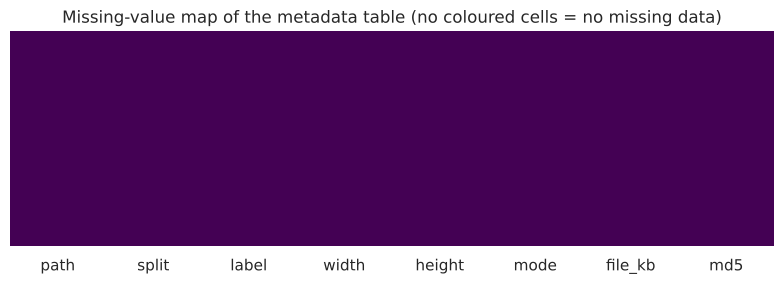

In [9]:
# Visualizing the missing values
fig, ax = plt.subplots(figsize=(8, 3))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=ax)
ax.set_title("Missing-value map of the metadata table (no coloured cells = no missing data)")
plt.tight_layout()
plt.show()

### What did you know about your dataset?

* The data holds **2,443 MRI images** in three ready-made splits: **train 1,695 (69%)**, **valid 502 (21%)** and **test 246 (10%)**, in four classes (glioma 805, meningioma 545, no_tumor 483, pituitary 610).
* Every image is **640 x 640 RGB JPG**; the scans are grey-scale stored in three channels.
* **No missing values, no unreadable files, no duplicate files, and no image shared between splits**, so there is no data leakage.
* The classes are **mildly imbalanced** (largest/smallest = 1.68 in train) and the class mix is the same in all splits (chi-square p = 0.47).
* The scans differ a lot in **plane (axial, coronal, sagittal) and contrast type**, which the EDA below shows is strongly linked to the class label.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
print(list(df.columns))

['path', 'split', 'label', 'width', 'height', 'mode', 'file_kb', 'md5']


In [11]:
# Dataset Describe
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
path,2443,2443,data/train/glioma/Tr-gl_0011_jpg.rf.61e213cb5a...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
split,2443,3,train,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,2443,4,glioma,805,NaN,NaN,NaN,NaN,NaN,NaN,NaN
width,2443.0,NaN,NaN,NaN,640.0,0.0,640.0,640.0,640.0,640.0,640.0
height,2443.0,NaN,NaN,NaN,640.0,0.0,640.0,640.0,640.0,640.0,640.0
mode,2443,1,RGB,2443,NaN,NaN,NaN,NaN,NaN,NaN,NaN
file_kb,2443.0,NaN,NaN,NaN,31.165728,9.092209,16.444336,24.048828,30.009766,36.708008,121.681641
md5,2443,2443,824a40e23a33bb4416c6e3ec253f8cdb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

| Column | Meaning |
|---|---|
| path | location of the image file |
| split | train / valid / test |
| label | **target**: glioma, meningioma, no_tumor, pituitary |
| width, height, mode | original image size (all 640x640) and colour mode (all RGB) |
| file_kb | JPEG file size in KB |
| md5 | hash of the file bytes, used to detect duplicates / leakage |
| mean_intensity | average grey level (brightness) of the scan resized to 256x256 |
| contrast | standard deviation of grey levels |
| head_area | fraction of non-black pixels, i.e. how much of the frame the head fills |
| sharpness | variance of the Laplacian, i.e. strength of edges / fine detail |
| bright_frac | fraction of very bright pixels (grey level > 200) |
| entropy | texture complexity of the grey-level histogram |
| color_dev | difference between colour channels (0 = pure grey) |

The model itself learns from the **pixels**; the image statistics are used only for exploration.

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
for col in df.columns:
    print(f"{col:10s} -> {df[col].nunique()} unique")
print("\nImage sizes found :", df[["width", "height"]].drop_duplicates().values.tolist())
print("Colour modes found:", df["mode"].unique().tolist())

path       -> 2443 unique
split      -> 3 unique
label      -> 4 unique
width      -> 1 unique
height     -> 1 unique
mode       -> 1 unique
file_kb    -> 2340 unique
md5        -> 2443 unique

Image sizes found : [[640, 640]]
Colour modes found: ['RGB']


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.
# 1) Read each image, resize to IMG_SIZE x IMG_SIZE (INTER_AREA = best for shrinking)
# 2) Cache the resized uint8 images in one array so later training never re-decodes JPEGs
# 3) Compute simple per-image statistics ("image features") so EDA charts are possible

def extract_features(path: str):
    """Return (resized RGB uint8 image, dict of statistics) for one file."""
    bgr = cv2.imread(path)
    if bgr is None:
        raise ValueError("cv2 could not decode the file")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    hist = np.bincount(gray.ravel(), minlength=256) / gray.size
    nz = hist[hist > 0]
    feats = {
        "mean_intensity": gray.mean(),                              # overall brightness
        "contrast": gray.std(),                                     # spread of grey levels
        "head_area": (gray > 25).mean(),                            # fraction of non-black pixels
        "sharpness": cv2.Laplacian(gray, cv2.CV_64F).var(),         # edge strength / detail
        "bright_frac": (gray > 200).mean(),                         # very bright pixels (enhancing lesions, fat, CSF)
        "entropy": float(-(nz * np.log2(nz)).sum()),                # texture complexity
        "color_dev": float(np.abs(rgb[..., 0].astype(int) - rgb[..., 2]).mean()),  # 0 = pure grey
    }
    return rgb, feats


images, feats, bad_idx = [], [], []
for i, p in enumerate(df["path"]):
    try:
        img, f = extract_features(p)
        images.append(img)
        feats.append(f)
    except Exception as e:
        print(f"Dropping {p}: {e}")
        bad_idx.append(i)

df = df.drop(index=bad_idx).reset_index(drop=True)
df = pd.concat([df, pd.DataFrame(feats)], axis=1)
X_all = np.stack(images)                       # shape (N, IMG_SIZE, IMG_SIZE, 3), uint8
y_all = df["label"].map({c: i for i, c in enumerate(CLASSES)}).values

# Cache for the modelling stages
np.save(ARTIFACT_DIR / "images.npy", X_all)
df.to_csv(ARTIFACT_DIR / "metadata.csv", index=False)

print("Image array:", X_all.shape, X_all.dtype, f"({X_all.nbytes/1e6:.0f} MB)")
df[["mean_intensity", "contrast", "head_area", "sharpness", "bright_frac", "entropy", "color_dev"]].describe().T.round(3)

Image array: (2443, 256, 256, 3) uint8 (480 MB)


,count,mean,std,min,25%,50%,75%,max
mean_intensity,2443.0,43.766,18.628,9.758,29.533,40.041,53.095,137.722
contrast,2443.0,43.809,11.306,22.005,36.693,41.373,47.614,91.365
head_area,2443.0,0.508,0.150,0.141,0.391,0.477,0.624,1.000
sharpness,2443.0,391.724,522.090,18.977,217.526,299.440,418.771,9245.042
bright_frac,2443.0,0.011,0.026,0.000,0.000,0.002,0.006,0.235
entropy,2443.0,5.659,0.898,2.040,4.818,5.768,6.471,7.839
color_dev,2443.0,0.007,0.134,0.000,0.000,0.000,0.000,3.362


### What all manipulations have you done and insights you found?

* Collected path, split, label and header information for every image and **removed macOS zip junk files** (`._*`).
* Checked duplicates (MD5), leakage across splits, and unreadable images - none found.
* **Resized every scan to 256 x 256** (INTER_AREA) and cached all images as one `uint8` array, so training never re-decodes JPEGs.
* Computed 7 per-image statistics for EDA.
* **Key insight:** the image statistics differ strongly between classes (e.g. median mean-intensity glioma 26.5 vs no_tumor 56.3). The classes were evidently scanned with different planes/sequences, so a model can partly 'cheat' by recognising the scan style rather than the tumour. This is treated as a risk in the modelling stages (augmentation, per-image normalisation, and checking errors).

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

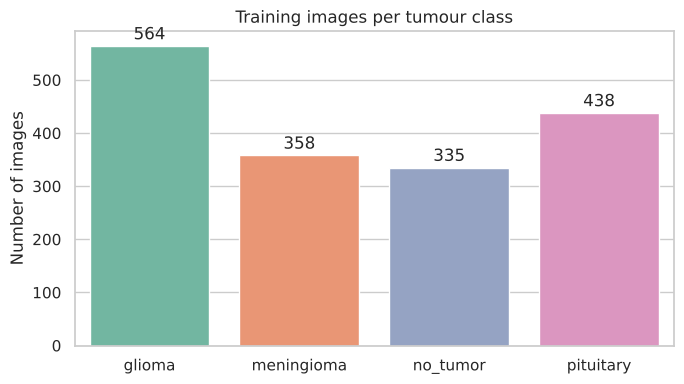

Largest / smallest class ratio: 1.68


In [14]:
# Chart - 1 : class distribution in the training set (Univariate, categorical)
train_df = df[df["split"] == "train"]
order = CLASSES
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=train_df, x="label", order=order, palette=PALETTE, ax=ax)
for c in ax.containers:
    ax.bar_label(c, padding=2)
ax.set_title("Training images per tumour class")
ax.set_xlabel("")
ax.set_ylabel("Number of images")
plt.tight_layout()
plt.show()
cnt = train_df["label"].value_counts()
print("Largest / smallest class ratio: %.2f" % (cnt.max() / cnt.min()))

##### 1. Why did you pick the specific chart?

A bar chart with counts is the simplest way to compare the size of categories, and class balance decides how we train (class weights, metrics).

##### 2. What is/are the insight(s) found from the chart?

Glioma is the largest class (564) and no_tumor the smallest (335); the ratio is 1.68. This is a mild imbalance, not a severe one.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: no oversampling is needed; class weights plus macro-averaged metrics are enough. Negative risk: with plain accuracy, the model could favour glioma (the biggest class) and still look good, which in a clinic would mean missed meningiomas or pituitary tumours.

#### Chart - 2

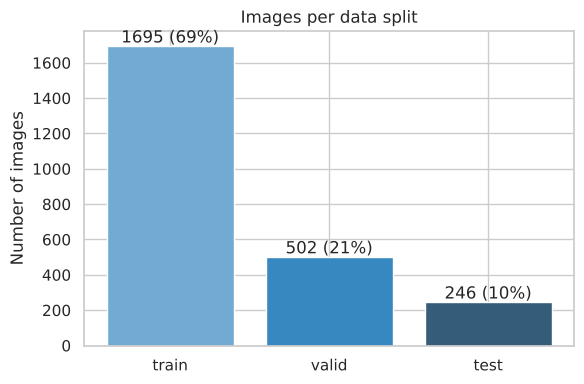

In [15]:
# Chart - 2 : how many images are in each split (Univariate, categorical)
fig, ax = plt.subplots(figsize=(6, 4))
split_cnt = df["split"].value_counts().reindex(SPLITS)
ax.bar(split_cnt.index, split_cnt.values, color=sns.color_palette("Blues_d", 3))
for i, v in enumerate(split_cnt.values):
    ax.text(i, v + 20, f"{v} ({v/len(df):.0%})", ha="center")
ax.set_title("Images per data split")
ax.set_ylabel("Number of images")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of split sizes shows at a glance whether we have enough data for training and an honest, separate test set.

##### 2. What is/are the insight(s) found from the chart?

69% of images are for training, 21% for validation and 10% (246 images) for testing.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: validation data allows early stopping and tuning without touching the test set. Negative: a 246-image test set is small, so each class has only about 50-80 test images and a few mistakes move the metrics noticeably; results should be quoted with that uncertainty.

#### Chart - 3

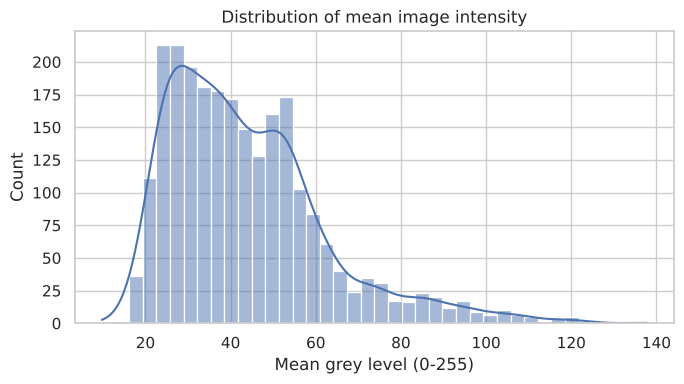

Skewness: 1.26


In [16]:
# Chart - 3 : distribution of mean brightness (Univariate, numerical)
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["mean_intensity"], bins=40, kde=True, color="#4C72B0", ax=ax)
ax.set_title("Distribution of mean image intensity")
ax.set_xlabel("Mean grey level (0-255)")
plt.tight_layout()
plt.show()
print("Skewness: %.2f" % df["mean_intensity"].skew())

##### 1. Why did you pick the specific chart?

A histogram with a KDE shows the overall shape and skew of one numeric variable.

##### 2. What is/are the insight(s) found from the chart?

Mean intensity is right-skewed (skewness 1.26): most scans are fairly dark (median 40) with a tail of very bright scans.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: it shows brightness varies a lot between scans, so we must normalise inputs and use brightness augmentation so the model does not depend on exposure. Negative: no direct negative growth; an un-normalised model would be unstable on bright outliers.

#### Chart - 4

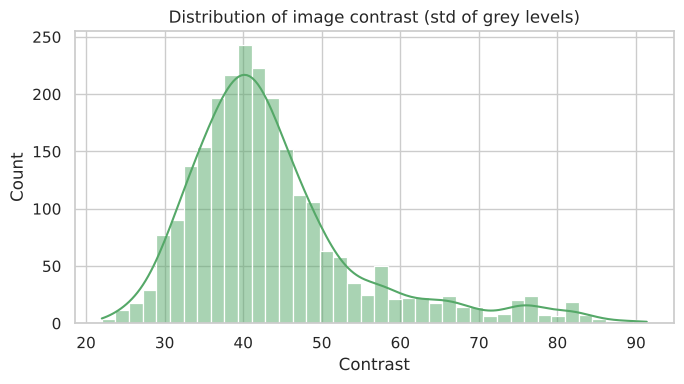

In [17]:
# Chart - 4 : distribution of contrast (Univariate, numerical)
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["contrast"], bins=40, kde=True, color="#55A868", ax=ax)
ax.set_title("Distribution of image contrast (std of grey levels)")
ax.set_xlabel("Contrast")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram of contrast shows how varied the image quality is, which affects how robust the model needs to be.

##### 2. What is/are the insight(s) found from the chart?

Contrast (grey-level standard deviation) is centred around 41 with a long tail up to 91, so there are both flat low-contrast scans and very high-contrast ones.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: supports adding contrast/brightness augmentation, which improves how the model works on scans from other scanners. Negative: very low-contrast scans may be hard to classify and could cause low-confidence predictions.

#### Chart - 5

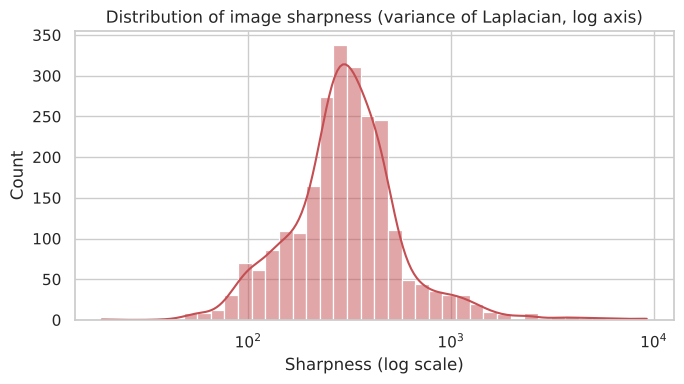

count    2443.0
mean      391.7
std       522.1
min        19.0
25%       217.5
50%       299.4
75%       418.8
max      9245.0
Name: sharpness, dtype: float64


In [18]:
# Chart - 5 : distribution of sharpness (Univariate, numerical, log scale)
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["sharpness"], bins=40, kde=True, log_scale=True, color="#C44E52", ax=ax)
ax.set_title("Distribution of image sharpness (variance of Laplacian, log axis)")
ax.set_xlabel("Sharpness (log scale)")
plt.tight_layout()
plt.show()
print(df["sharpness"].describe().round(1))

##### 1. Why did you pick the specific chart?

Sharpness spans a wide range, so a log-scale histogram makes the whole distribution readable.

##### 2. What is/are the insight(s) found from the chart?

Sharpness is strongly skewed (median 299, max 9,245): most scans have moderate detail while a minority are extremely sharp.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: it confirms scans come from different protocols or resolutions; training on this variety helps generalisation. Negative: the very sharp scans are rare, so the model may perform worse on them.

#### Chart - 6

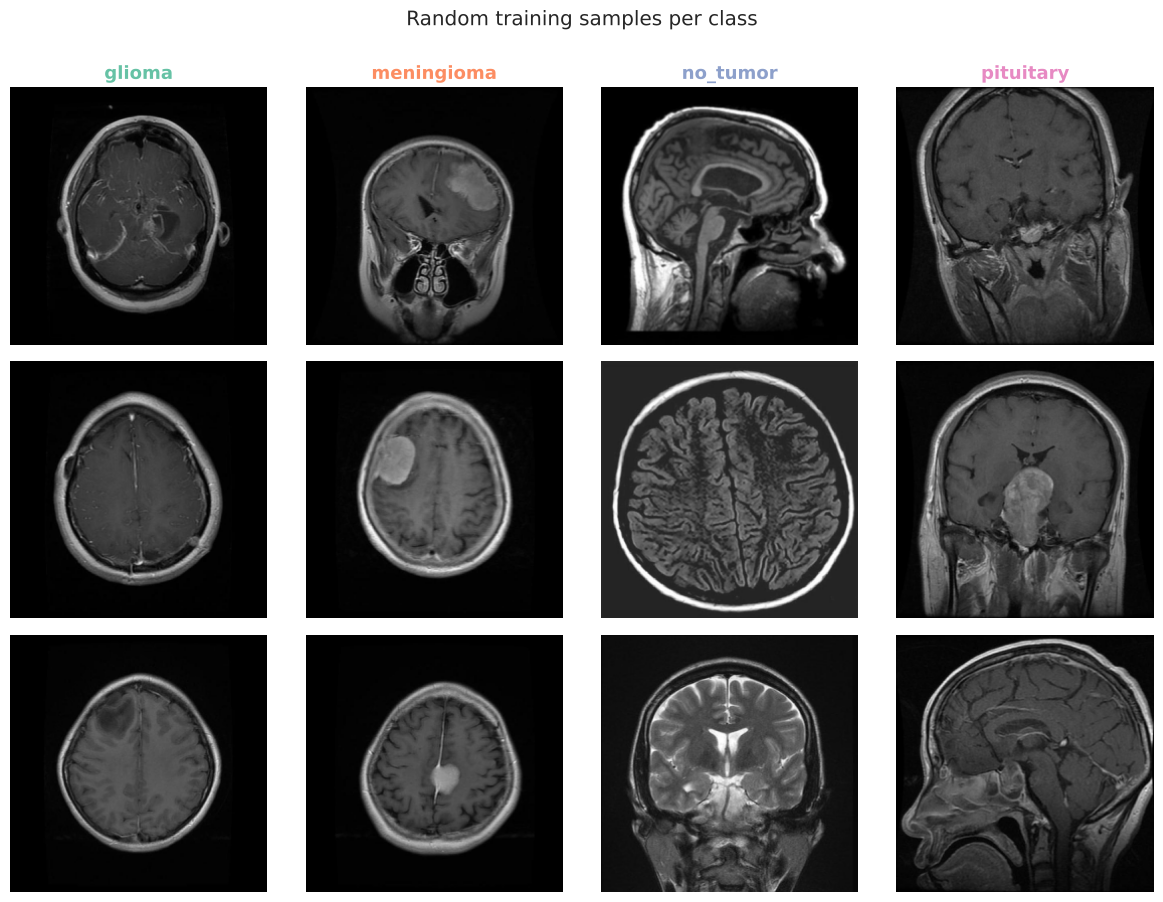

In [19]:
# Chart - 6 : random sample of scans from each class (qualitative view)
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for j, cls in enumerate(CLASSES):
    idx = rng.choice(np.where((df["label"] == cls) & (df["split"] == "train"))[0], 3, replace=False)
    for i, k in enumerate(idx):
        axes[i, j].imshow(X_all[k])
        axes[i, j].axis("off")
        if i == 0:
            axes[i, j].set_title(cls, fontsize=13, color=PALETTE[cls], fontweight="bold")
plt.suptitle("Random training samples per class", y=1.0)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Looking at real images is essential in medical imaging; a grid with the same number of examples per class allows a fair visual comparison.

##### 2. What is/are the insight(s) found from the chart?

The scans come from different planes (axial, coronal, sagittal) and different contrast settings. Tumours are often small and subtle, especially pituitary lesions near the skull base.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: it justifies using only realistic augmentation (small rotations, horizontal flip, brightness) and no vertical flip, which would give an unrealistic upside-down brain. Negative: small lesions mean we should not shrink the images too much (see Chart 16).

#### Chart - 7

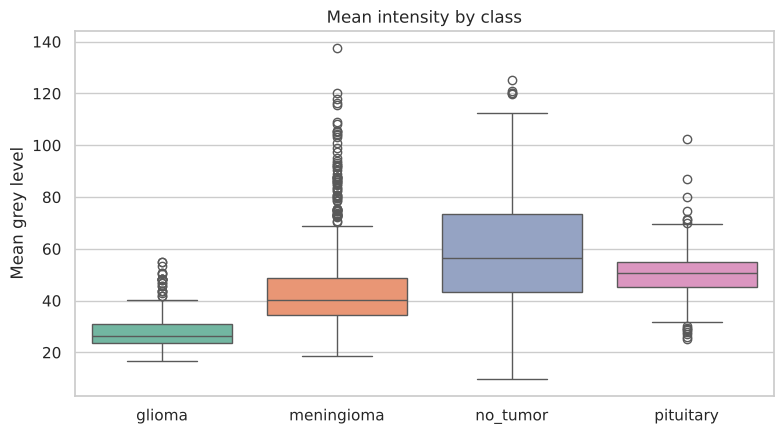

label
glioma        26.5
meningioma    40.1
no_tumor      56.3
pituitary     50.8
Name: mean_intensity, dtype: float64


In [20]:
# Chart - 7 : mean intensity by class (Bivariate, numerical vs categorical)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="label", y="mean_intensity", order=CLASSES, palette=PALETTE, ax=ax)
ax.set_title("Mean intensity by class")
ax.set_xlabel("")
ax.set_ylabel("Mean grey level")
plt.tight_layout()
plt.show()
print(df.groupby("label")["mean_intensity"].median().round(1))

##### 1. Why did you pick the specific chart?

A box plot compares the median and spread of a numeric variable across the classes and shows outliers.

##### 2. What is/are the insight(s) found from the chart?

Median brightness differs strongly by class: glioma 26.5 (darkest), meningioma 40.1, pituitary 50.8, no_tumor 56.3 (brightest).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: brightness-type features contain class signal, so a CNN can learn quickly. Negative and important: a difference this large mostly reflects scan type/protocol, not tumour biology. A model might learn 'dark scan = glioma' and fail on scans from a hospital with other settings, which would be a risk in real use.

#### Chart - 8

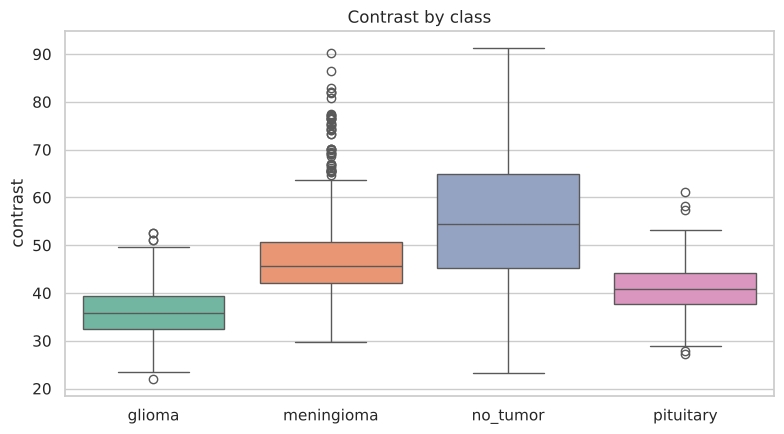

label
glioma        35.8
meningioma    45.7
no_tumor      54.4
pituitary     40.8
Name: contrast, dtype: float64


In [21]:
# Chart - 8 : contrast by class (Bivariate, numerical vs categorical)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="label", y="contrast", order=CLASSES, palette=PALETTE, ax=ax)
ax.set_title("Contrast by class")
ax.set_xlabel("")
plt.tight_layout()
plt.show()
print(df.groupby("label")["contrast"].median().round(1))

##### 1. Why did you pick the specific chart?

A second box plot, for contrast, checks whether the class differences in Chart 7 also show up in another statistic.

##### 2. What is/are the insight(s) found from the chart?

Median contrast is lowest for glioma (35.8), then pituitary (40.8), meningioma (45.7) and no_tumor (54.4), the same ordering as brightness for most classes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: more evidence that the classes are visually separable. Negative: again this is a sign of dataset-specific acquisition differences, so we will check the model with brightness/contrast augmentation and look at its mistakes.

#### Chart - 9

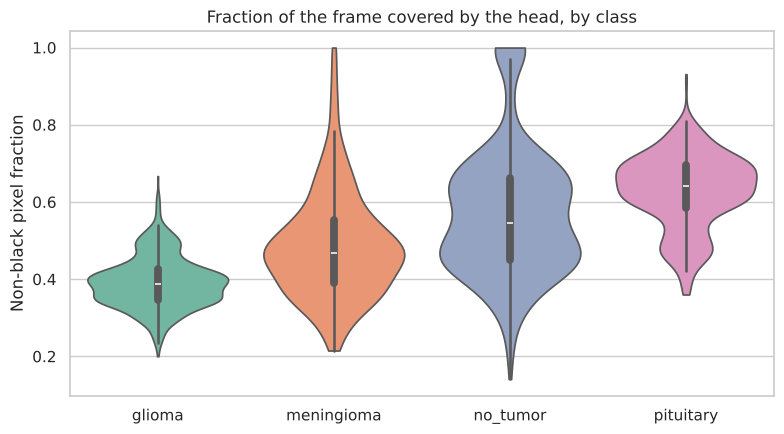

label
glioma        0.388
meningioma    0.469
no_tumor      0.545
pituitary     0.641
Name: head_area, dtype: float64


In [22]:
# Chart - 9 : head/brain area filling the frame, by class (Bivariate, numerical vs categorical)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=df, x="label", y="head_area", order=CLASSES, palette=PALETTE, cut=0, ax=ax)
ax.set_title("Fraction of the frame covered by the head, by class")
ax.set_xlabel("")
ax.set_ylabel("Non-black pixel fraction")
plt.tight_layout()
plt.show()
print(df.groupby("label")["head_area"].median().round(3))

##### 1. Why did you pick the specific chart?

A violin plot shows the full shape of the distribution, not only the median, and head size depends on the view of the scan.

##### 2. What is/are the insight(s) found from the chart?

The head fills the frame most in pituitary scans (median 0.64) and least in glioma scans (0.39); meningioma is 0.47 and no_tumor 0.55. Pituitary scans are mostly close-up coronal/sagittal views.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: the model can use view-related cues. Negative: since pituitary scans differ in framing, the model might recognise the view instead of the tumour; random zoom and shift augmentation reduces this risk.

#### Chart - 10

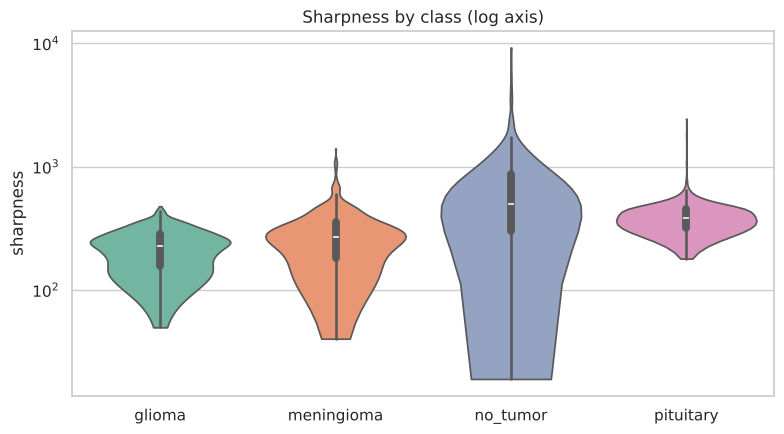

label
glioma        227.1
meningioma    269.6
no_tumor      494.2
pituitary     380.9
Name: sharpness, dtype: float64


In [23]:
# Chart - 10 : sharpness by class (Bivariate, numerical vs categorical)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=df, x="label", y="sharpness", order=CLASSES, palette=PALETTE, cut=0, ax=ax)
ax.set_yscale("log")
ax.set_title("Sharpness by class (log axis)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()
print(df.groupby("label")["sharpness"].median().round(1))

##### 1. Why did you pick the specific chart?

A violin plot on a log axis shows differences in sharpness across classes even though the values span two orders of magnitude.

##### 2. What is/are the insight(s) found from the chart?

no_tumor scans are the sharpest (median 494) and glioma the least sharp (227), with pituitary 381 and meningioma 270.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: texture and edge information differs by class, which helps a CNN. Negative: sharpness differences could be due to the imaging settings, so again the model could pick up on image quality rather than disease; evaluating on the untouched test set and checking confusion patterns is needed.

#### Chart - 11

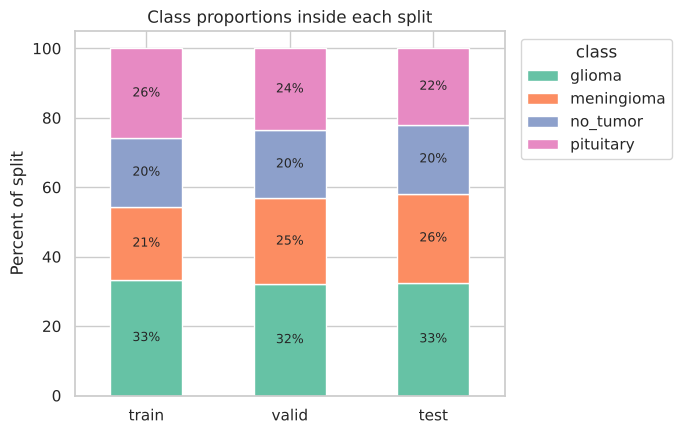

In [24]:
# Chart - 11 : class mix inside each split (Bivariate, categorical vs categorical)
mix = pd.crosstab(df["split"], df["label"], normalize="index").reindex(SPLITS)[CLASSES] * 100
ax = mix.plot(kind="bar", stacked=True, figsize=(7, 4.5), color=[PALETTE[c] for c in CLASSES])
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", label_type="center", fontsize=9)
ax.set_title("Class proportions inside each split")
ax.set_ylabel("Percent of split")
ax.set_xlabel("")
plt.xticks(rotation=0)
ax.legend(title="class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A 100% stacked bar compares category proportions across splits and is the right tool to test whether the splits are comparable.

##### 2. What is/are the insight(s) found from the chart?

The class mix is almost identical in train, valid and test (glioma about 33%, no_tumor about 20%).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: the validation score will predict the test score well because the splits are stratified, and there is no distribution shift between them. No negative impact.

#### Chart - 12

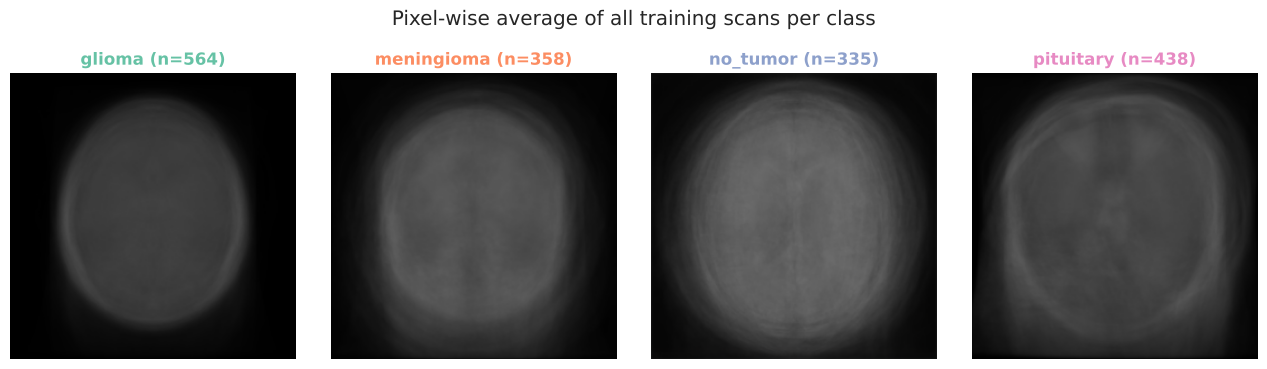

In [25]:
# Chart - 12 : the "average scan" of each class (Multivariate: every pixel position)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, cls in zip(axes, CLASSES):
    idx = np.where((df["label"] == cls) & (df["split"] == "train"))[0]
    ax.imshow(X_all[idx].mean(axis=0).astype(np.uint8))
    ax.set_title(f"{cls} (n={len(idx)})", color=PALETTE[cls], fontweight="bold")
    ax.axis("off")
plt.suptitle("Pixel-wise average of all training scans per class", y=1.02)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

An average image per class shows the typical position, size and brightness of the head for each class using every pixel together.

##### 2. What is/are the insight(s) found from the chart?

The glioma average is the darkest and the head sits as a small, centred oval (mostly axial slices); the pituitary average is wider with a brighter skull outline; the no_tumor average is the brightest and fills the most uniform area.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: it explains what the model may learn from layout and brightness. Negative: the averages differ in layout, which means class-specific acquisition habits exist in this dataset; we should expect high accuracy on this data but be careful about claiming the same performance on other hospitals.

#### Chart - 13

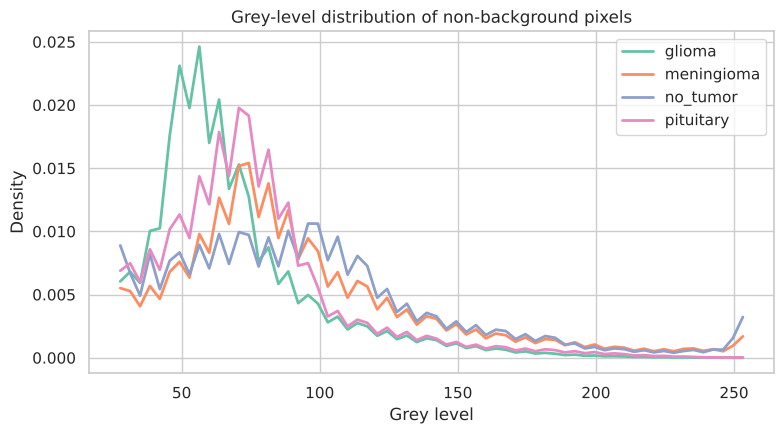

In [26]:
# Chart - 13 : grey-level histogram of head pixels per class (Multivariate: class x intensity)
fig, ax = plt.subplots(figsize=(8, 4.5))
for cls in CLASSES:
    idx = np.where((df["label"] == cls) & (df["split"] == "train"))[0][:150]
    pix = X_all[idx][..., 0].ravel()
    pix = pix[pix > 25]                                      # ignore the black background
    h, edges = np.histogram(pix, bins=64, range=(26, 255), density=True)
    ax.plot((edges[:-1] + edges[1:]) / 2, h, label=cls, color=PALETTE[cls], lw=2)
ax.set_title("Grey-level distribution of non-background pixels")
ax.set_xlabel("Grey level")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Overlaid density curves compare the grey-level distributions of all four classes in one plot, ignoring the black background.

##### 2. What is/are the insight(s) found from the chart?

Glioma scans have a sharp peak at dark grey levels (about 50-60) and few bright pixels; no_tumor has a much heavier bright tail and a spike at the maximum (255); meningioma and pituitary lie in between.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: the histograms are clearly different, so the problem is learnable. Negative: the differences are in global brightness, not in tumour shape, so normalising each image (and using augmentation) is needed to force the model to look at structures.

#### Chart - 14 - Correlation Heatmap

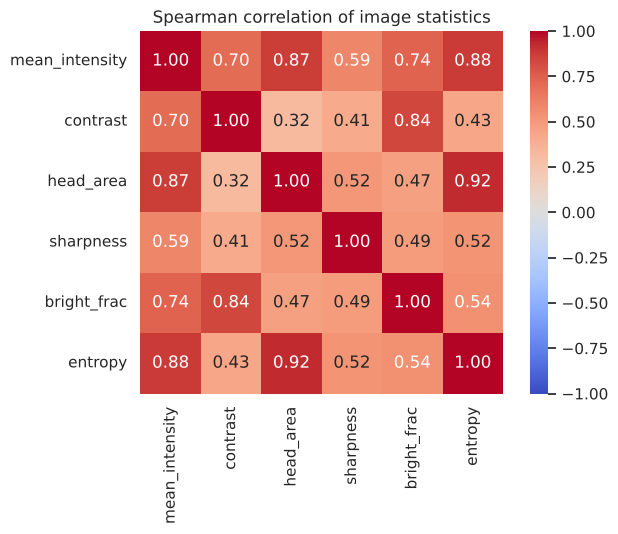

In [27]:
# Correlation Heatmap visualization code
FEATS = ["mean_intensity", "contrast", "head_area", "sharpness", "bright_frac", "entropy"]
corr = df[FEATS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation of image statistics")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap shows which numeric image statistics move together, so we know which ones are redundant. The Spearman method is used because the variables are skewed.

##### 2. What is/are the insight(s) found from the chart?

Mean intensity, head area and entropy are strongly related (0.87 to 0.92), and contrast and bright fraction are also strongly related (0.84). Sharpness is only moderately correlated with the others (0.4 to 0.6). These statistics describe overall exposure and framing, so there are really only two or three independent ideas among the six.

#### Chart - 15 - Pair Plot

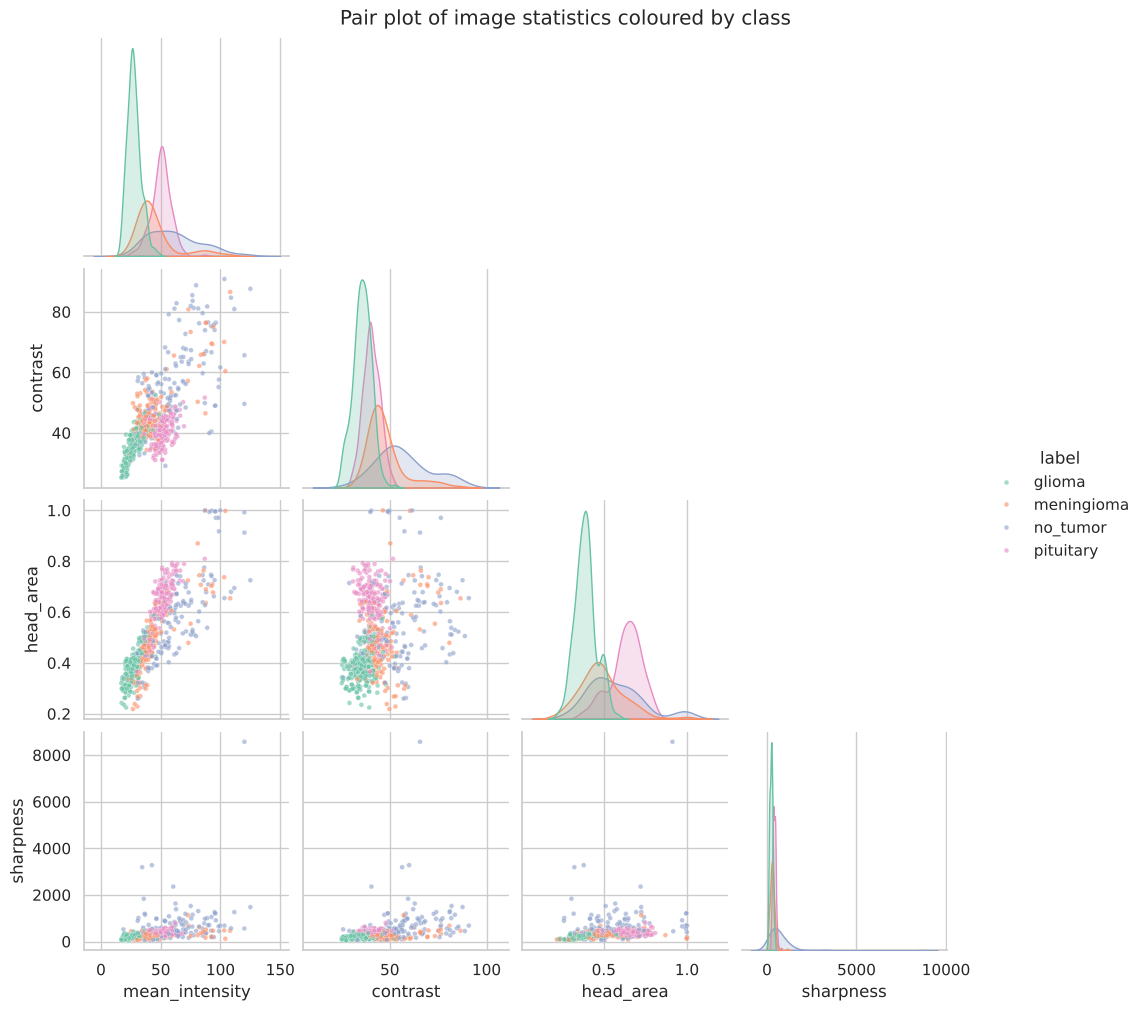

In [28]:
# Pair Plot visualization code
sample = df.sample(min(700, len(df)), random_state=SEED)
g = sns.pairplot(sample, vars=["mean_intensity", "contrast", "head_area", "sharpness"],
                 hue="label", hue_order=CLASSES, palette=PALETTE, corner=True,
                 plot_kws={"s": 12, "alpha": 0.6})
g.fig.suptitle("Pair plot of image statistics coloured by class", y=1.01)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot coloured by class shows every pairwise relationship and class overlap in one view, which makes it a good multivariate summary.

##### 2. What is/are the insight(s) found from the chart?

The classes form partly separate clouds - glioma sits at low intensity, low head area and low contrast, no_tumor at high values - but they overlap clearly in the middle, especially meningioma and pituitary. This means simple statistics are not enough on their own, and a CNN that learns shapes and textures is needed.

#### Chart - 16 - Image-size study

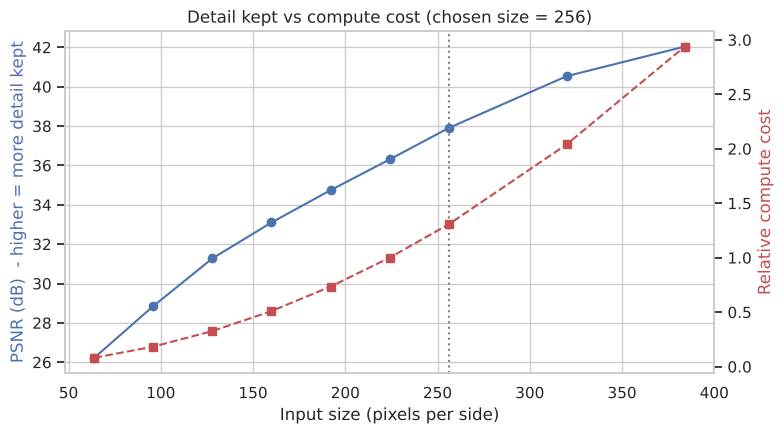

 size  PSNR_dB  relative_cost
   64    26.23           0.08
   96    28.86           0.18
  128    31.28           0.33
  160    33.10           0.51
  192    34.74           0.73
  224    36.30           1.00
  256    37.90           1.31
  320    40.54           2.04
  384    42.04           2.94


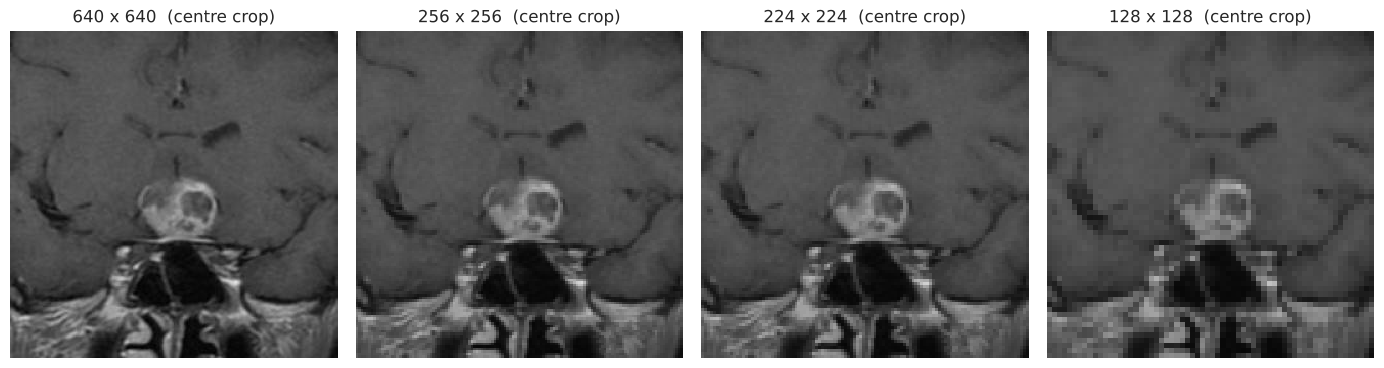

In [29]:
# Chart - 16 : choosing the image size - detail kept vs compute cost
# For a sample of full-resolution (640 px) scans: shrink to S x S, enlarge back to 640 and
# measure PSNR against the original. Higher PSNR = less detail lost by shrinking.
sizes = [64, 96, 128, 160, 192, 224, 256, 320, 384]
rng = np.random.RandomState(SEED)
sample_paths = rng.choice(df["path"], 60, replace=False)
psnr = {s: [] for s in sizes}
for p in sample_paths:
    full = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2GRAY)
    for s in sizes:
        small = cv2.resize(full, (s, s), interpolation=cv2.INTER_AREA)
        back = cv2.resize(small, full.shape[::-1], interpolation=cv2.INTER_LINEAR)
        mse = np.mean((full.astype(float) - back.astype(float)) ** 2)
        psnr[s].append(10 * np.log10(255 ** 2 / mse))
mean_psnr = [np.mean(psnr[s]) for s in sizes]
rel_cost = [(s / 224) ** 2 for s in sizes]                   # conv cost grows with pixel count

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(sizes, mean_psnr, "o-", color="#4C72B0", label="Detail kept (PSNR, dB)")
ax1.set_xlabel("Input size (pixels per side)")
ax1.set_ylabel("PSNR (dB)  - higher = more detail kept", color="#4C72B0")
ax2 = ax1.twinx()
ax2.plot(sizes, rel_cost, "s--", color="#C44E52", label="Relative compute vs 224")
ax2.set_ylabel("Relative compute cost", color="#C44E52")
ax2.grid(False)
ax1.axvline(IMG_SIZE, color="gray", ls=":")
ax1.set_title(f"Detail kept vs compute cost (chosen size = {IMG_SIZE})")
plt.tight_layout()
plt.show()
print(pd.DataFrame({"size": sizes, "PSNR_dB": np.round(mean_psnr, 2), "relative_cost": np.round(rel_cost, 2)}).to_string(index=False))

# Visual check: the same small-lesion scan at several sizes (nearest-neighbour so pixels stay visible)
pit = df[(df["label"] == "pituitary") & (df["split"] == "train")]["path"].iloc[0]
full = cv2.cvtColor(cv2.imread(pit), cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, s in zip(axes, [640, 256, 224, 128]):
    im = cv2.resize(full, (s, s), interpolation=cv2.INTER_AREA)
    c0, c1 = int(s * 0.25), int(s * 0.75)                      # zoom into the central region
    ax.imshow(im[c0:c1, c0:c1], interpolation="nearest")
    ax.set_title(f"{s} x {s}  (centre crop)")
    ax.axis("off")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The image size is the most important design choice for the CNN. Plotting the detail kept (PSNR after shrinking and enlarging back) against compute cost shows the trade-off directly, and the zoomed images show it visually.

##### 2. What is/are the insight(s) found from the chart?

Detail kept rises steadily with size (PSNR 31.3 dB at 128, 36.3 dB at 224, 37.9 dB at 256, 40.5 dB at 320), while compute cost grows with the square of the size (1.31x for 256 and 2.04x for 320 relative to 224). At 128 x 128 the lesion in the pituitary example becomes blocky, whereas 224 and 256 still show its internal structure. **Decision: 256 x 256**, because it keeps about 1.6 dB more detail than 224 for only about 30% more compute, and the pretrained networks work with any input size.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: a justified choice protects small lesions, which are the cases where a miss matters most clinically, without making training too slow. Negative: 256 is 31% more expensive than 224 and 640 would be about 8 times more, so the training time is longer than with the usual 224; this is acceptable on a GPU.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

From the charts, three testable statements:

1. Brightness differs between the four tumour classes (Charts 7 and 13).
2. The class proportions are the same in train, valid and test (Chart 11).
3. Scans with a tumour differ from no-tumour scans in their share of very bright pixels (Chart 13).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** The distribution of mean intensity is the same in all four classes.
**H1:** At least one class has a different mean-intensity distribution.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
# H1: mean intensity differs between the four classes -> Kruskal-Wallis
groups = [df.loc[df["label"] == c, "mean_intensity"] for c in CLASSES]
h_stat, p1 = stats.kruskal(*groups)
print("Medians:", {c: round(g.median(), 2) for c, g in zip(CLASSES, groups)})
print(f"Kruskal-Wallis H = {h_stat:.2f}, p-value = {p1:.4g}")
print("Reject H0" if p1 < 0.05 else "Fail to reject H0", "at alpha = 0.05")

Medians: {'glioma': np.float64(26.47), 'meningioma': np.float64(40.11), 'no_tumor': np.float64(56.31), 'pituitary': np.float64(50.83)}
Kruskal-Wallis H = 1416.23, p-value = 8.861e-307
Reject H0 at alpha = 0.05


##### Which statistical test have you done to obtain P-Value?

Kruskal-Wallis H test (alpha = 0.05). Result: H = 1416, p = 8.9e-307, so **we reject H0**: brightness differs significantly between classes (medians 26.5, 40.1, 56.3 and 50.8).

##### Why did you choose the specific statistical test?

There are more than two independent groups and the intensity is right-skewed (not normal), so the rank-based Kruskal-Wallis test is safer than one-way ANOVA. The practical meaning is that image brightness is linked to the label, which is a possible shortcut for the model.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** The class proportions are independent of the split (the splits have the same class mix).
**H1:** The class proportions differ between train, valid and test.

#### 2. Perform an appropriate statistical test.

In [31]:
# Perform Statistical Test to obtain P-Value
# H2: class proportions are the same in train / valid / test -> chi-square test of independence
table = pd.crosstab(df["label"], df["split"])
chi2, p2, dof, _ = stats.chi2_contingency(table)
print(table)
print(f"\nChi-square = {chi2:.2f}, dof = {dof}, p-value = {p2:.4g}")
print("Reject H0" if p2 < 0.05 else "Fail to reject H0", "at alpha = 0.05")

split       test  train  valid
label                         
glioma        80    564    161
meningioma    63    358    124
no_tumor      49    335     99
pituitary     54    438    118

Chi-square = 5.59, dof = 6, p-value = 0.4702
Fail to reject H0 at alpha = 0.05


##### Which statistical test have you done to obtain P-Value?

Chi-square test of independence on the class x split table (alpha = 0.05). Result: chi-square = 5.59, dof = 6, p = 0.47, so **we fail to reject H0**: the splits have statistically the same class mix.

##### Why did you choose the specific statistical test?

Both variables are categorical and we compare observed counts with the counts expected under independence, which is exactly what the chi-square test does. All expected counts are above 5, so the test is valid. The practical meaning is that the validation score is a fair preview of the test score.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** Tumour scans and no-tumour scans have the same distribution of the bright-pixel fraction.
**H1:** The two distributions are different (two-sided).

#### 2. Perform an appropriate statistical test.

In [32]:
# Perform Statistical Test to obtain P-Value
# H3: scans with a tumour have a different share of very bright pixels than no-tumour scans
# -> Mann-Whitney U (two-sided; distributions are skewed, so a rank test is safer than a t-test)
tumour = df.loc[df["label"] != "no_tumor", "bright_frac"]
healthy = df.loc[df["label"] == "no_tumor", "bright_frac"]
u_stat, p3 = stats.mannwhitneyu(tumour, healthy, alternative="two-sided")
print(f"Median bright fraction  tumour: {tumour.median():.4f}   no tumour: {healthy.median():.4f}")
print(f"Mann-Whitney U = {u_stat:.0f}, p-value = {p3:.4g}")
print("Reject H0" if p3 < 0.05 else "Fail to reject H0", "at alpha = 0.05")

Median bright fraction  tumour: 0.0010   no tumour: 0.0203
Mann-Whitney U = 173688, p-value = 2.704e-103
Reject H0 at alpha = 0.05


##### Which statistical test have you done to obtain P-Value?

Mann-Whitney U test (two-sided, alpha = 0.05). Result: U = 173,688, p = 2.7e-103, so **we reject H0**. The direction is the opposite of what a naive guess would be: no-tumour scans have a much higher bright fraction (median 0.020) than tumour scans (0.001).

##### Why did you choose the specific statistical test?

We compare two independent groups and the bright fraction is extremely skewed (most values are near 0), so a rank test is more appropriate than a t-test. The surprising direction is explained by scan type: the no-tumour scans are brighter T2-like slices where fluid appears white, so this is again an acquisition difference, not a tumour feature.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [33]:
# Handling Missing Values & Missing Value Imputation
# Images have no "missing cells", so we check the things that could silently be missing:
# empty rows in the metadata, a mismatch between table and image array, and blank (all-black) scans.
print("Missing values in metadata :", int(df.isnull().sum().sum()))
print("Rows in table vs images    :", len(df), "vs", len(X_all))
assert len(df) == len(X_all), "metadata and image array are out of sync"
blank = int((df["mean_intensity"] < 1).sum())
print("Blank (all-black) scans     :", blank)

Missing values in metadata : 0
Rows in table vs images    : 2443 vs 2443
Blank (all-black) scans     : 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

None were needed. The metadata has no empty cells, the table and the image array match (2,443 rows each), and there are no blank (all-black) scans. For image data, 'imputation' does not apply: an image is either readable or not, and every file was readable.

### 2. Handling Outliers

In [34]:
# Handling Outliers & Outlier treatments
# IQR rule on the image statistics (outlier = beyond 1.5 x IQR from the quartiles)
rows = []
for col in ["mean_intensity", "contrast", "head_area", "sharpness", "bright_frac", "entropy"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    mask = (df[col] < lo) | (df[col] > hi)
    rows.append({"feature": col, "outliers": int(mask.sum()), "percent": round(100 * mask.mean(), 1),
                 "most_affected_class": df.loc[mask, "label"].mode().iloc[0] if mask.any() else "-"})
print(pd.DataFrame(rows).to_string(index=False))
print("\nDecision: no image is removed. Every outlier is a valid scan (a different plane or "
      "sequence); instead, augmentation makes the model robust to them.")

       feature  outliers  percent most_affected_class
mean_intensity        81      3.3            no_tumor
      contrast       177      7.2            no_tumor
     head_area        32      1.3            no_tumor
     sharpness       170      7.0            no_tumor
   bright_frac       374     15.3            no_tumor
       entropy         1      0.0            no_tumor

Decision: no image is removed. Every outlier is a valid scan (a different plane or sequence); instead, augmentation makes the model robust to them.


##### What all outlier treatment techniques have you used and why did you use those techniques?

The IQR rule flags many scans as outliers on some statistics (e.g. 15% on bright_frac, 7% on contrast and sharpness), and most of them are **no_tumor** scans, which are the brightest and sharpest class. **No image was removed.** These are valid scans in a different plane or sequence, not errors, and deleting them would remove most of the healthy-class variety. Instead, brightness/contrast augmentation and normalisation make the CNN robust to them.

### 3. Categorical Encoding

In [35]:
# Encode your categorical columns
# The only categorical variable that the model needs is the target. Map class name <-> integer.
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}
df["target"] = df["label"].map(CLASS_TO_IDX)
assert (df["target"].values == y_all).all()
print(CLASS_TO_IDX)

{'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


#### What all categorical encoding techniques have you used & why did you use those techniques?

Only the target needs encoding. **Label encoding** (glioma = 0, meningioma = 1, no_tumor = 2, pituitary = 3) is used because PyTorch's cross-entropy loss expects integer class indices; the network's output layer then has 4 neurons with a softmax. One-hot encoding is not needed with this loss, and the classes have no order, so the integers are only identifiers.

### 4. Textual Data Preprocessing
**Not applicable.** This is an image dataset; there is no text. The ten text steps below (contractions, lower-casing, tokenisation, vectorisation, etc.) are left empty on purpose.

#### 1. Expand Contraction

In [36]:
# Expand Contraction

#### 2. Lower Casing

In [37]:
# Lower Casing

#### 3. Removing Punctuations

In [38]:
# Remove Punctuations

#### 4. Removing URLs & Removing words and digits contain digits.

In [39]:
# Remove URLs & Remove words and digits contain digits

#### 5. Removing Stopwords & Removing White spaces

In [40]:
# Remove Stopwords

In [41]:
# Remove White spaces

#### 6. Rephrase Text

In [42]:
# Rephrase Text

#### 7. Tokenization

In [43]:
# Tokenization

#### 8. Text Normalization

In [44]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)

##### Which text normalization technique have you used and why?

Not applicable (image dataset).

#### 9. Part of speech tagging

In [45]:
# POS Taging

#### 10. Text Vectorization

In [46]:
# Vectorizing Text

##### Which text vectorization technique have you used and why?

Not applicable (image dataset).

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [47]:
# Manipulate Features to minimize feature correlation and create new features
# For a CNN the "features" are the pixels. The pipeline (applied identically to every model) is:
#   uint8 image (0-255)  ->  float in [0, 1]  ->  standardise with ImageNet mean/std
# ImageNet statistics are used because the pretrained models in Stage 3 were trained with them.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
print("Per-image statistics (brightness, contrast, ...) are NOT fed to the model. They are only used for EDA,")
print("because they are strongly tied to the class (see Charts 7-13) and would encourage shortcut learning.")

Per-image statistics (brightness, contrast, ...) are NOT fed to the model. They are only used for EDA,
because they are strongly tied to the class (see Charts 7-13) and would encourage shortcut learning.


#### 2. Feature Selection

In [48]:
# Select your features wisely to avoid overfitting
# A CNN learns its own features, so no manual selection is needed. As a sanity check we measure how much
# class information is hidden in the 6 simple image statistics alone (train on train, test on valid).
from sklearn.ensemble import RandomForestClassifier

FEATS = ["mean_intensity", "contrast", "head_area", "sharpness", "bright_frac", "entropy"]
tr = df["split"] == "train"
va = df["split"] == "valid"
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
rf.fit(df.loc[tr, FEATS], df.loc[tr, "target"])
rf_acc = accuracy_score(df.loc[va, "target"], rf.predict(df.loc[va, FEATS]))
print(f"Validation accuracy from 6 global image statistics only: {rf_acc:.3f}   (chance = 0.25)")
print(pd.Series(rf.feature_importances_, index=FEATS).sort_values(ascending=False).round(3).to_string())

Validation accuracy from 6 global image statistics only: 0.845   (chance = 0.25)


mean_intensity    0.220
entropy           0.164
contrast          0.164
bright_frac       0.158
head_area         0.151
sharpness         0.144


##### What all feature selection methods have you used  and why?

No manual feature selection was used, because a CNN learns its own features from the pixels and the convolution filters are selected by training. As a check, a random forest trained on 6 hand-made global image statistics (brightness, contrast, head area, sharpness, bright fraction, entropy) reaches **84.5% validation accuracy** (chance is 25%). So a large part of the class information sits in simple 'scan style' statistics. These statistics are deliberately **not** given to the CNN, and 84.5% becomes the baseline that the CNN has to clearly beat to prove it learned something beyond scan style.

##### Which all features you found important and why?

In the random-forest check, mean intensity (0.22) is the most important statistic and the other five are almost equal (0.14-0.16); none dominates alone. This agrees with the EDA: brightness is the strongest single signal, but exposure, framing and texture all carry class information. For the CNN, the important 'features' are the learned shapes and textures of lesions, which we look at again in the explainability step.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

**Yes.** Three transformations are used: (1) **resize** 640 -> 256 pixels (Chart 16) so training is feasible and small lesions are kept; (2) **conversion to float and ImageNet standardisation**, so the optimiser works with well-scaled inputs and the pretrained models in Stage 3 see the statistics they were trained with; (3) **random augmentation of the training images only** - horizontal flip, rotation up to 15 degrees, shift up to 8%, zoom 0.9-1.1 and brightness/contrast jitter of 40%. Augmentation increases the effective training set size, reduces over-fitting, and the strong brightness/contrast jitter specifically reduces the risk of learning scan exposure instead of the tumour. Vertical flip is not used because an upside-down brain is not realistic.

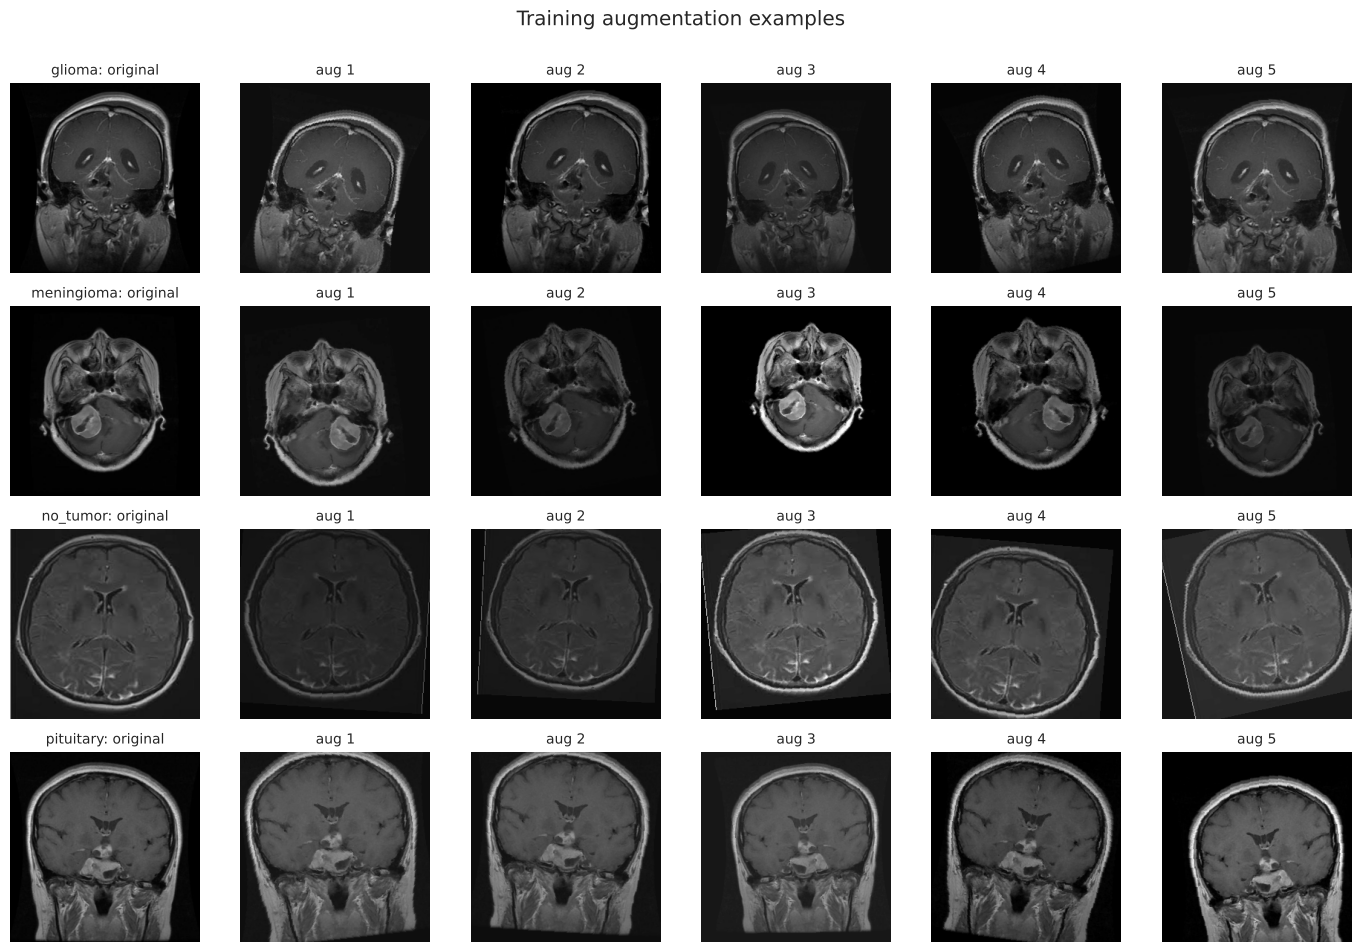

In [49]:
# Transform Your data  (+ data augmentation)
# Augmentation = random, realistic changes of the TRAINING images only. Validation / test images are never augmented.
train_tf = v2.Compose([
    v2.RandomHorizontalFlip(p=0.5),                                   # left-right flip is anatomically plausible
    v2.RandomAffine(degrees=15, translate=(0.08, 0.08), scale=(0.9, 1.1)),   # small rotation, shift, zoom
    v2.ColorJitter(brightness=0.4, contrast=0.4),                     # exposure differences between scanners/sequences
    v2.ToDtype(torch.float32, scale=True),                            # uint8 0-255 -> float 0-1
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
# NO vertical flip: an upside-down brain never occurs in practice.

# Show one scan from each class with 5 random augmentations
show_tf = v2.Compose(train_tf.transforms[:3])
fig, axes = plt.subplots(4, 6, figsize=(14, 9.5))
for r, cls in enumerate(CLASSES):
    k = int(np.where((df["label"] == cls) & (df["split"] == "train"))[0][5])
    base = torch.from_numpy(X_all[k]).permute(2, 0, 1)
    axes[r, 0].imshow(X_all[k]); axes[r, 0].set_title(f"{cls}: original", fontsize=10)
    for c in range(1, 6):
        axes[r, c].imshow(show_tf(base).permute(1, 2, 0).numpy()); axes[r, c].set_title(f"aug {c}", fontsize=10)
for a in axes.ravel():
    a.axis("off")
plt.suptitle("Training augmentation examples", y=1.0)
plt.tight_layout()
plt.show()

### 6. Data Scaling

In [50]:
# Scaling your data
# Compare the real training-set pixel statistics with the ImageNet ones used for standardisation.
train_idx_all = np.where(df["split"] == "train")[0]
sub = X_all[train_idx_all][:, ::4, ::4].astype(np.float32) / 255.0      # subsample pixels for speed
print("Train pixel mean (R,G,B):", sub.mean(axis=(0, 1, 2)).round(3), " ImageNet:", IMAGENET_MEAN)
print("Train pixel std  (R,G,B):", sub.std(axis=(0, 1, 2)).round(3), " ImageNet:", IMAGENET_STD)

example = eval_tf(torch.from_numpy(X_all[train_idx_all[0]]).permute(2, 0, 1))
print("\nOne scan after scaling: min %.2f  max %.2f  mean %.2f" % (example.min(), example.max(), example.mean()))

Train pixel mean (R,G,B): [0.171 0.171 0.171]  ImageNet: (0.485, 0.456, 0.406)


Train pixel std  (R,G,B): [0.192 0.192 0.192]  ImageNet: (0.229, 0.224, 0.225)

One scan after scaling: min -2.12  max 2.29  mean -1.41


##### Which method have you used to scale you data and why?

**Standardisation with the ImageNet channel mean and std** after dividing pixels by 255 (so values are 0-1 first). The training set's own pixel statistics (mean 0.17, std 0.19) are lower than ImageNet's because MRI scans are mostly dark background; we still use the ImageNet values for all models so that the custom CNN and the pretrained networks are compared under exactly the same input pipeline, and the pretrained weights work as intended.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No. A CNN reduces dimensionality itself: strided convolution and max-pooling shrink the 256 x 256 x 3 input step by step and global average pooling produces one small feature vector per image. Applying PCA on raw pixels would destroy the spatial structure that convolutions rely on.

In [51]:
# Dimensionality Reduction (If needed)
# Not needed: convolution + pooling layers already reduce the 256x256x3 input to a small feature vector,
# and a CNN with global average pooling does this by itself.
print("Input size per image:", tuple(X_all.shape[1:]), "-> handled by the CNN, no PCA applied.")

Input size per image: (256, 256, 3) -> handled by the CNN, no PCA applied.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Not applicable. No dimensionality reduction technique was applied outside the network.

### 8. Data Splitting

In [52]:
# Split your data to train and test. Choose Splitting ratio wisely.
# The dataset already comes in three separate folders (no image is shared between them, see duplicates check).
# We keep that split: train 69% / valid 21% / test 10%.
BATCH_SIZE = 32
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0

class MRIDataset(Dataset):
    """Wraps the cached uint8 images; applies a transform each time an image is requested."""
    def __init__(self, images, targets, transform):
        self.images, self.targets, self.transform = images, targets, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        img = torch.from_numpy(self.images[i]).permute(2, 0, 1)      # HWC uint8 -> CHW uint8
        return self.transform(img), int(self.targets[i])

split_idx = {s: np.where(df["split"].values == s)[0] for s in SPLITS}
X_tr, y_tr = X_all[split_idx["train"]], y_all[split_idx["train"]]
X_va, y_va = X_all[split_idx["valid"]], y_all[split_idx["valid"]]
X_te, y_te = X_all[split_idx["test"]], y_all[split_idx["test"]]

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(MRIDataset(X_tr, y_tr, train_tf), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, generator=g)
val_loader = DataLoader(MRIDataset(X_va, y_va, eval_tf), batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(MRIDataset(X_te, y_te, eval_tf), batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
print({k: len(v) for k, v in split_idx.items()}, "| batches per epoch:", len(train_loader))

{'train': 1695, 'valid': 502, 'test': 246} | batches per epoch: 53


##### What data splitting ratio have you used and why?

The dataset already comes with three separate folders, and we keep them: **train 1,695 (69%) / validation 502 (21%) / test 246 (10%)**. The checks show no duplicate image and no image shared between folders, so the test set is a fair, unseen set, and the chi-square test (Hypothesis 2) shows the same class mix in all three. The validation set is used for early stopping and tuning; the test set is touched only for the final comparison.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

**Mildly.** The largest class (glioma, 564) is 1.68 times the smallest (no_tumor, 335), and the smallest class still has 20% of the data. This is not a severe imbalance, but without care the model would favour glioma a little.

In [53]:
# Handling Imbalanced Dataset (If needed)
# Class weights: rare classes get a larger weight in the loss. weight_c = N / (n_classes * n_c)
counts = np.bincount(y_tr, minlength=len(CLASSES))
class_weights = torch.tensor(len(y_tr) / (len(CLASSES) * counts), dtype=torch.float32)
print(dict(zip(CLASSES, counts)))
print("Class weights:", dict(zip(CLASSES, class_weights.numpy().round(2))))

{'glioma': np.int64(564), 'meningioma': np.int64(358), 'no_tumor': np.int64(335), 'pituitary': np.int64(438)}
Class weights: {'glioma': np.float32(0.75), 'meningioma': np.float32(1.18), 'no_tumor': np.float32(1.26), 'pituitary': np.float32(0.97)}


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

**Class weights** in the cross-entropy loss (glioma 0.75, meningioma 1.18, no_tumor 1.26, pituitary 0.97 - rare classes count more). With only a 1.7x ratio, oversampling or synthetic data (SMOTE) would add duplicated or artificial scans without real benefit, and weights have no cost in data. We also report **macro-averaged** precision, recall and F1, and the per-class confusion matrix, so a weak minority class cannot hide behind overall accuracy.

## ***7. ML Model Implementation***

### ML Model - 1

In [54]:
# ML Model - 1 Implementation : custom CNN trained from scratch

class CustomCNN(nn.Module):
    """Strided 5x5 stem -> 4 x [Conv-BN-ReLU, Conv-BN-ReLU, MaxPool, Dropout2d] -> GAP -> Dropout -> Linear."""
    def __init__(self, width=16, dropout=0.4, n_classes=len(CLASSES)):
        super().__init__()
        def conv_bn(i, o):
            return [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)]
        layers = [nn.Conv2d(3, width, 5, stride=2, padding=2, bias=False), nn.BatchNorm2d(width), nn.ReLU(inplace=True)]
        c_in = width
        for mult in (2, 4, 8, 16):
            c_out = width * mult
            layers += conv_bn(c_in, c_out) + conv_bn(c_out, c_out) + [nn.MaxPool2d(2), nn.Dropout2d(0.1)]
            c_in = c_out
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))
    def forward(self, x):
        return self.head(self.features(x))


# ---------- shared training / evaluation helpers (re-used by every model in this notebook) ----------
def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over a loader. Trains if an optimizer is given, otherwise only evaluates."""
    training = optimizer is not None
    model.train(training)
    if training:                                  # frozen BatchNorm layers must keep their pretrained statistics
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
                m.eval()
    loss_sum, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            loss = criterion(out, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
    return loss_sum / n, correct / n


def fit(model, name, epochs, lr=1e-3, weight_decay=1e-4, patience=5, verbose=True):
    """Train with AdamW + ReduceLROnPlateau. EarlyStopping and ModelCheckpoint on validation loss."""
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, wait = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        scheduler.step(vl)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        if vl < best_loss - 1e-4:                               # ModelCheckpoint: keep the best weights
            best_loss, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
            torch.save(best_state, ARTIFACT_DIR / f"{name}.pt")
        else:
            wait += 1
        if verbose:
            print(f"[{name}] epoch {ep:2d}/{epochs}  train loss {tl:.3f} acc {ta:.3f} | "
                  f"val loss {vl:.3f} acc {va:.3f} | lr {optimizer.param_groups[0]['lr']:.1e} | {time.time()-t0:.0f}s")
        if wait >= patience:                                    # EarlyStopping
            print(f"[{name}] early stopping at epoch {ep} (best val loss {best_loss:.3f})")
            break
    model.load_state_dict(best_state)
    return model, hist


@torch.no_grad()
def predict(model, loader):
    """Return true labels, predicted labels and class probabilities."""
    model.eval()
    ys, ps = [], []
    for xb, yb in loader:
        ps.append(torch.softmax(model(xb.to(DEVICE)), dim=1).cpu())
        ys.append(yb)
    probs = torch.cat(ps).numpy()
    return torch.cat(ys).numpy(), probs.argmax(1), probs


def metrics_table(y_true, y_pred):
    """Accuracy and macro precision / recall / F1 (macro = every class counts equally)."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f}


def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="validation")
    ax[0].set_title(f"{title}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["train_acc"], label="train"); ax[1].plot(hist["val_acc"], label="validation")
    ax[1].set_title(f"{title}: accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
    ax[0].set_title(f"{title}: counts"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
    ax[1].set_title(f"{title}: row-normalised (= recall)"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
    plt.tight_layout(); plt.show()


# ---------- Fit the baseline custom CNN ----------
EPOCHS_CNN = 15
cnn_base = CustomCNN(width=16, dropout=0.4)
print("Parameters: %.2f M" % (sum(p.numel() for p in cnn_base.parameters()) / 1e6))
cnn_base, hist_base = fit(cnn_base, "custom_cnn_base", epochs=EPOCHS_CNN, lr=1e-3, weight_decay=1e-4, patience=4)

# Predict on the validation set
yv_true, yv_pred, yv_prob = predict(cnn_base, val_loader)

Parameters: 1.18 M


[custom_cnn_base] epoch  1/15  train loss 1.159 acc 0.505 | val loss 1.765 acc 0.388 | lr 1.0e-03 | 176s


[custom_cnn_base] epoch  2/15  train loss 1.006 acc 0.599 | val loss 0.709 acc 0.753 | lr 1.0e-03 | 175s


[custom_cnn_base] epoch  3/15  train loss 0.992 acc 0.608 | val loss 0.839 acc 0.683 | lr 1.0e-03 | 165s


[custom_cnn_base] epoch  4/15  train loss 0.991 acc 0.592 | val loss 2.424 acc 0.400 | lr 1.0e-03 | 168s


...

[custom_cnn_base] epoch 11/15  train loss 0.738 acc 0.701 | val loss 0.554 acc 0.787 | lr 2.5e-04 | 154s


[custom_cnn_base] epoch 12/15  train loss 0.723 acc 0.714 | val loss 0.518 acc 0.803 | lr 2.5e-04 | 162s


[custom_cnn_base] epoch 13/15  train loss 0.687 acc 0.740 | val loss 0.525 acc 0.793 | lr 2.5e-04 | 169s


[custom_cnn_base] epoch 14/15  train loss 0.681 acc 0.752 | val loss 3.225 acc 0.331 | lr 2.5e-04 | 163s


[custom_cnn_base] epoch 15/15  train loss 0.700 acc 0.729 | val loss 0.614 acc 0.755 | lr 1.3e-04 | 156s


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Model:** a convolutional neural network built from scratch (1.18 M parameters). A strided 5x5 stem reads the 256x256 scan, then four blocks of *Conv-BatchNorm-ReLU, Conv-BatchNorm-ReLU, MaxPool, Dropout2d* (16 -> 32 -> 64 -> 128 -> 256 channels) learn edges, textures and shapes; global average pooling, dropout (0.4) and a 4-way linear layer give the class scores. BatchNorm stabilises learning, dropout reduces over-fitting, and the strided stem keeps the full 256-pixel input affordable. Trained with AdamW, class-weighted cross-entropy, ReduceLROnPlateau, early stopping and best-weights checkpointing.

**Performance (validation set, 502 images):** accuracy **0.803**, macro precision 0.804, macro recall 0.795, macro F1 0.792. Per class: glioma recall 0.89, pituitary 0.93, no_tumor 0.75, **meningioma only 0.60** (24 meningiomas were called pituitary and 13 no_tumor). Pituitary has the lowest precision (0.71) because many other scans are wrongly called pituitary.

**Two warnings from the curves:** (1) training accuracy is only about 73%, so the model is **under-fitting**, not over-fitting; (2) validation loss jumps wildly between epochs (0.52 up to 3.2), a sign of unstable BatchNorm statistics between heavily augmented training batches and clean validation images. The reported scores are those of the best epoch, so they are optimistic compared with the typical epoch. Also, the 6-statistics random forest from the feature-selection step scored 0.845 on the same set, **so this CNN has not yet beaten the 'scan style' baseline.**

**Business meaning of the metrics:** *recall* per class is the share of real tumours of that type that are found, so a low meningioma recall means missed or mislabelled patients, which is the costly error in a clinic; *precision* is how often a flagged type is correct, so low pituitary precision means false alarms and unnecessary specialist work; *F1* balances the two; *accuracy* alone would hide a weak class.

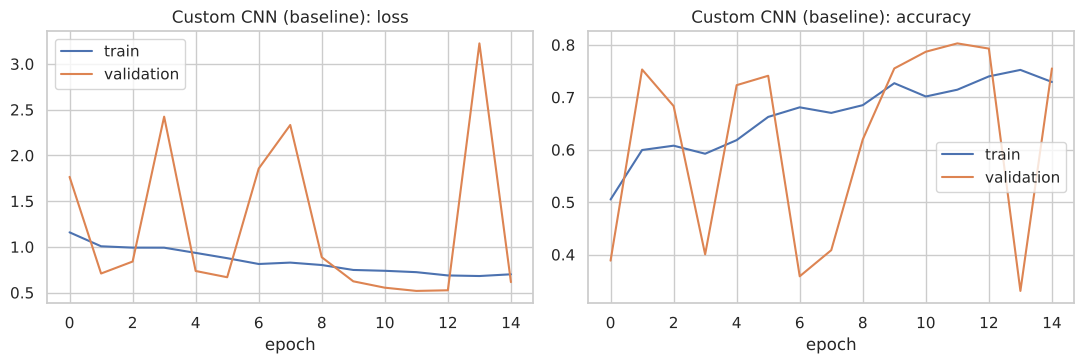

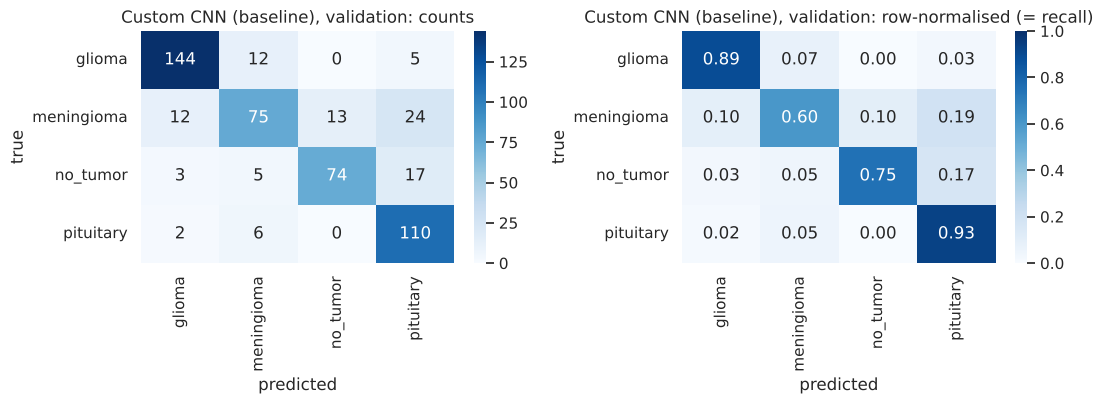

              precision    recall  f1-score   support

      glioma      0.894     0.894     0.894       161
  meningioma      0.765     0.605     0.676       124
    no_tumor      0.851     0.747     0.796        99
   pituitary      0.705     0.932     0.803       118

    accuracy                          0.803       502
   macro avg      0.804     0.795     0.792       502
weighted avg      0.809     0.803     0.799       502



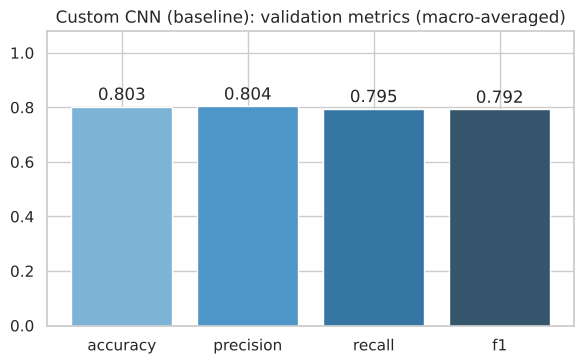

In [55]:
# Visualizing evaluation Metric Score chart
plot_history(hist_base, "Custom CNN (baseline)")
plot_confusion(yv_true, yv_pred, "Custom CNN (baseline), validation")

base_metrics = metrics_table(yv_true, yv_pred)
print(classification_report(yv_true, yv_pred, target_names=CLASSES, digits=3))

fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(base_metrics.keys(), base_metrics.values(), color=sns.color_palette("Blues_d", 4))
ax.bar_label(bars, fmt="%.3f", padding=2)
ax.set_ylim(0, 1.08); ax.set_title("Custom CNN (baseline): validation metrics (macro-averaged)")
plt.tight_layout(); plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

trial 1: lr=0.0003 dropout=0.5 wd=0.01 -> val loss 0.704, val acc 0.761


trial 2: lr=0.001 dropout=0.4 wd=0.001 -> val loss 0.797, val acc 0.731


trial 3: lr=0.001 dropout=0.3 wd=0.0001 -> val loss 0.750, val acc 0.701
 trial     lr  dropout  weight_decay  val_loss  accuracy  precision  recall     f1
     1 0.0003      0.5        0.0100    0.7038    0.7610     0.7528  0.7520 0.7504
     3 0.0010      0.3        0.0001    0.7496    0.7012     0.7256  0.6799 0.6649
     2 0.0010      0.4        0.0010    0.7974    0.7311     0.7523  0.7116 0.7137


[custom_cnn_tuned] epoch  1/20  train loss 1.201 acc 0.496 | val loss 0.909 acc 0.681 | lr 3.0e-04 | 154s


[custom_cnn_tuned] epoch  2/20  train loss 1.027 acc 0.585 | val loss 0.737 acc 0.737 | lr 3.0e-04 | 156s


...

[custom_cnn_tuned] epoch  5/20  train loss 0.927 acc 0.616 | val loss 0.670 acc 0.787 | lr 3.0e-04 | 162s


[custom_cnn_tuned] epoch  6/20  train loss 0.927 acc 0.627 | val loss 0.728 acc 0.711 | lr 3.0e-04 | 161s


[custom_cnn_tuned] epoch  7/20  train loss 0.892 acc 0.640 | val loss 0.877 acc 0.649 | lr 1.5e-04 | 159s


[custom_cnn_tuned] epoch  8/20  train loss 0.855 acc 0.667 | val loss 0.694 acc 0.737 | lr 1.5e-04 | 158s


[custom_cnn_tuned] epoch  9/20  train loss 0.825 acc 0.677 | val loss 1.760 acc 0.382 | lr 1.5e-04 | 157s
[custom_cnn_tuned] early stopping at epoch 9 (best val loss 0.657)


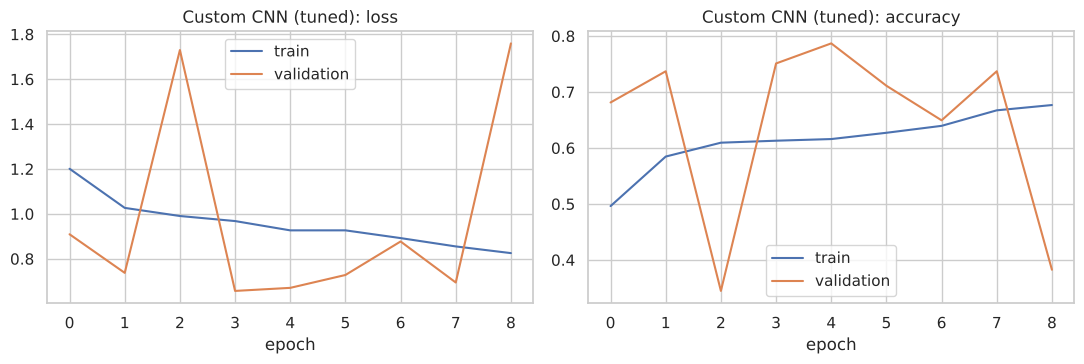

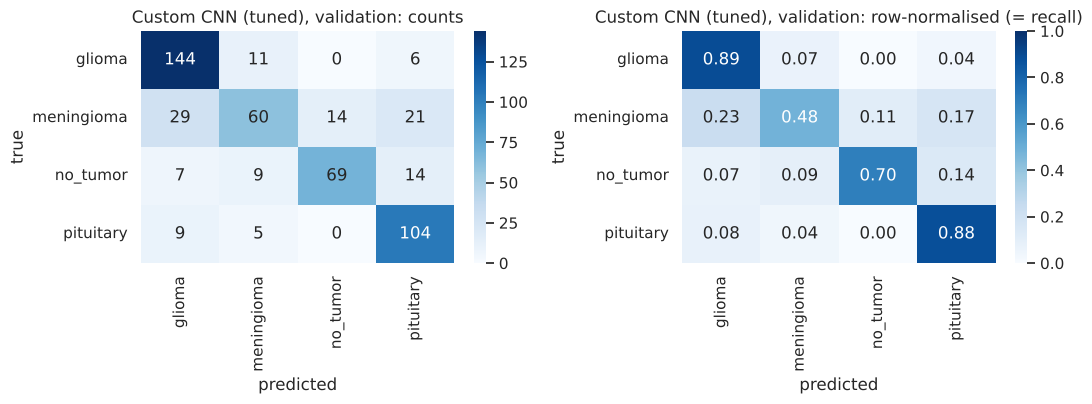

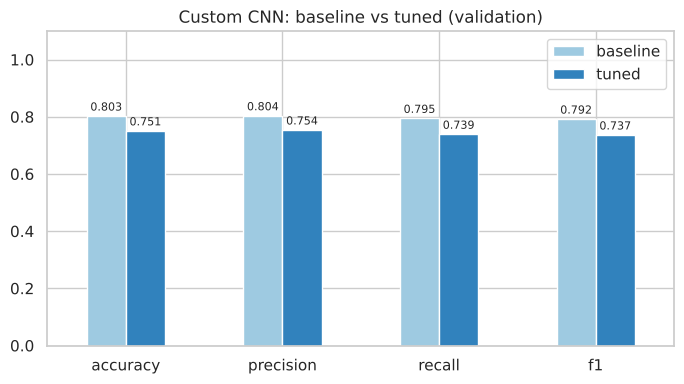

           baseline   tuned
accuracy     0.8028  0.7510
precision    0.8039  0.7541
recall       0.7947  0.7392
f1           0.7922  0.7365


In [56]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (Random Search)
# Cross-validation note: k-fold CV would train the network k times. On this CPU-only run that is too slow, so the
# fixed validation split (502 images, never used for training) is used to compare settings. See the answer below.
import itertools

search_space = {"lr": [3e-4, 1e-3, 2e-3], "dropout": [0.3, 0.4, 0.5], "weight_decay": [1e-4, 1e-3, 1e-2]}
N_TRIALS, EPOCHS_TRIAL = 3, 4
rng_search = np.random.RandomState(SEED)
all_combos = list(itertools.product(*search_space.values()))
trial_ids = rng_search.choice(len(all_combos), N_TRIALS, replace=False)

trial_rows = []
for t, ci in enumerate(trial_ids, 1):
    lr, dr, wd = all_combos[ci]
    torch.manual_seed(SEED)
    m, h = fit(CustomCNN(width=16, dropout=dr), f"trial{t}", epochs=EPOCHS_TRIAL, lr=lr, weight_decay=wd,
               patience=EPOCHS_TRIAL, verbose=False)
    yt, yp, _ = predict(m, val_loader)
    r = metrics_table(yt, yp)
    trial_rows.append({"trial": t, "lr": lr, "dropout": dr, "weight_decay": wd, "val_loss": min(h["val_loss"]), **r})
    print(f"trial {t}: lr={lr} dropout={dr} wd={wd} -> val loss {min(h['val_loss']):.3f}, val acc {r['accuracy']:.3f}")

trials_df = pd.DataFrame(trial_rows).sort_values("val_loss")
print(trials_df.round(4).to_string(index=False))
best = trials_df.iloc[0]

# Fit the Algorithm with the best setting for the full training budget
torch.manual_seed(SEED)
cnn_tuned = CustomCNN(width=16, dropout=float(best["dropout"]))
cnn_tuned, hist_tuned = fit(cnn_tuned, "custom_cnn_tuned", epochs=EPOCHS_CNN + 5, lr=float(best["lr"]),
                            weight_decay=float(best["weight_decay"]), patience=5)

# Predict on the model
yv_true, yv_pred_t, yv_prob_t = predict(cnn_tuned, val_loader)
tuned_metrics = metrics_table(yv_true, yv_pred_t)

# Updated evaluation metric score chart: baseline vs tuned
plot_history(hist_tuned, "Custom CNN (tuned)")
plot_confusion(yv_true, yv_pred_t, "Custom CNN (tuned), validation")
cmp = pd.DataFrame({"baseline": base_metrics, "tuned": tuned_metrics})
ax = cmp.plot(kind="bar", figsize=(7, 4), color=["#9ecae1", "#3182bd"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=2, fontsize=8)
ax.set_ylim(0, 1.1); ax.set_title("Custom CNN: baseline vs tuned (validation)"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
print(cmp.round(4))

##### Which hyperparameter optimization technique have you used and why?

**Random search** over learning rate {3e-4, 1e-3, 2e-3}, dropout {0.3, 0.4, 0.5} and weight decay {1e-4, 1e-3, 1e-2}: 3 random combinations of the 27 possible, each trained for 4 epochs and ranked by validation loss. Random search was chosen because it explores several settings at once at a fixed small budget, while a full grid (27 networks, about 5 minutes each on this CPU) was not affordable. **Cross-validation was not run:** k-fold CV would train the network k times; instead the separate validation set (502 images, never trained on) was used, which is the usual practice for deep networks. On a GPU, k-fold CV can be added with the same `fit` function.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**No - the tuned model is worse.** The search picked lr = 3e-4, dropout = 0.5, weight decay = 0.01 (validation loss 0.704, against 0.750 and 0.797 for the other two). Trained for the full budget it stopped early at epoch 9 and reached validation accuracy **0.751** and macro F1 **0.737**, compared with 0.803 and 0.792 for the baseline.

Why, as far as the evidence shows: (1) the search is tiny (3 trials x 4 epochs) and the validation loss is very noisy because of the instability described above, so ranking by it is unreliable; (2) the chosen lower learning rate learns more slowly and the model was still under-fitting when early stopping fired; (3) the stronger regularisation (dropout 0.5, weight decay 0.01) adds to under-fitting in a model that is already not fitting the training data. So the honest conclusion is: **tuning did not help here because the real problem is training stability and capacity, not the choice among these three settings.** This is a result to report, not to hide; the next step is fixing the instability and trying transfer learning.

### ML Model - 1b : the same CNN on head-cropped, brightness-normalised scans

**Why this experiment?** Three pieces of evidence say the plain CNN can lean on shortcuts: (1) the classes differ strongly in brightness and framing (Charts 7-13), (2) a random forest that sees only 6 global image statistics scores 84.5% on validation, more than the CNN, and (3) Grad-CAM (Stage 4) shows the CNN's attention often sitting on the black background and skull edge instead of the brain. Two changes to the **input** (not the model) remove those cues:
1. **Crop to the head** (square box around the non-black region), so every head fills the frame in the same way.
2. **Per-image brightness normalisation** (the 99th percentile of head pixels is mapped to the same grey level in every scan).

The architecture, training budget and hyper-parameters are exactly those of the baseline, so any difference comes from the input change.

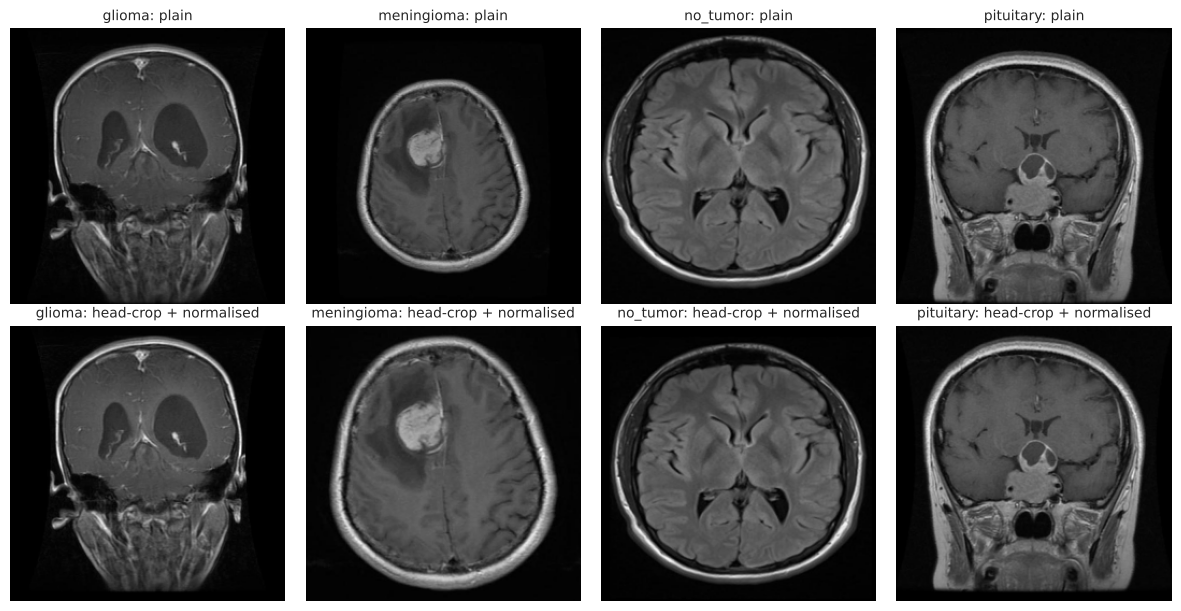

Mean head_area of the cropped scans: 0.56 (plain: 0.51)


[custom_cnn_headcrop] epoch  1/15  train loss 1.299 acc 0.394 | val loss 1.098 acc 0.560 | lr 1.0e-03 | 165s


[custom_cnn_headcrop] epoch  2/15  train loss 1.156 acc 0.489 | val loss 1.048 acc 0.584 | lr 1.0e-03 | 162s


[custom_cnn_headcrop] epoch  3/15  train loss 1.112 acc 0.535 | val loss 0.974 acc 0.620 | lr 1.0e-03 | 157s


[custom_cnn_headcrop] epoch  4/15  train loss 1.081 acc 0.545 | val loss 0.940 acc 0.604 | lr 1.0e-03 | 158s


...

[custom_cnn_headcrop] epoch 11/15  train loss 0.843 acc 0.674 | val loss 0.791 acc 0.693 | lr 1.0e-03 | 160s


[custom_cnn_headcrop] epoch 12/15  train loss 0.800 acc 0.709 | val loss 0.808 acc 0.661 | lr 1.0e-03 | 163s


[custom_cnn_headcrop] epoch 13/15  train loss 0.763 acc 0.699 | val loss 0.637 acc 0.753 | lr 5.0e-04 | 171s


[custom_cnn_headcrop] epoch 14/15  train loss 0.685 acc 0.737 | val loss 0.540 acc 0.795 | lr 5.0e-04 | 164s


[custom_cnn_headcrop] epoch 15/15  train loss 0.659 acc 0.745 | val loss 0.764 acc 0.691 | lr 5.0e-04 | 161s


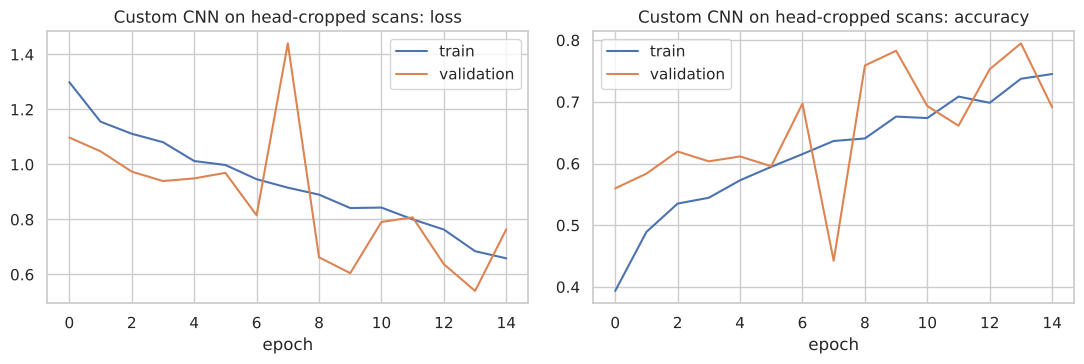

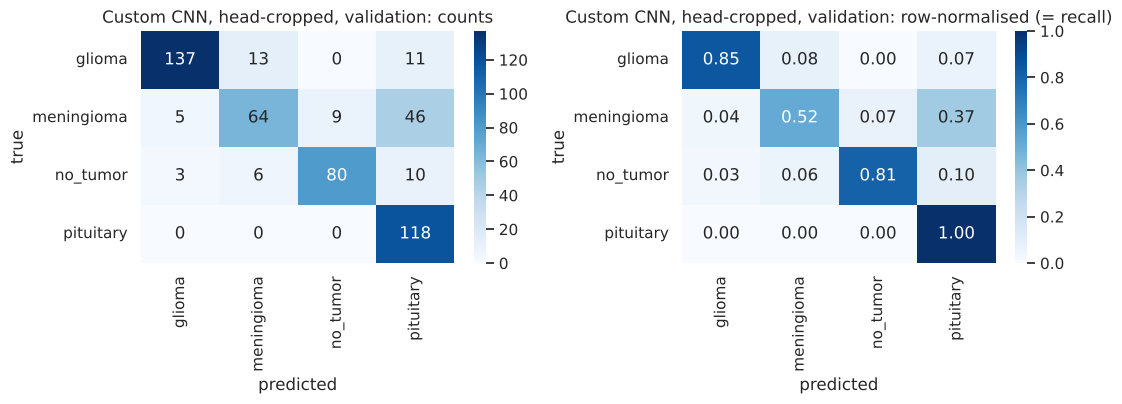

              precision    recall  f1-score   support

      glioma      0.945     0.851     0.895       161
  meningioma      0.771     0.516     0.618       124
    no_tumor      0.899     0.808     0.851        99
   pituitary      0.638     1.000     0.779       118

    accuracy                          0.795       502
   macro avg      0.813     0.794     0.786       502
weighted avg      0.821     0.795     0.791       502



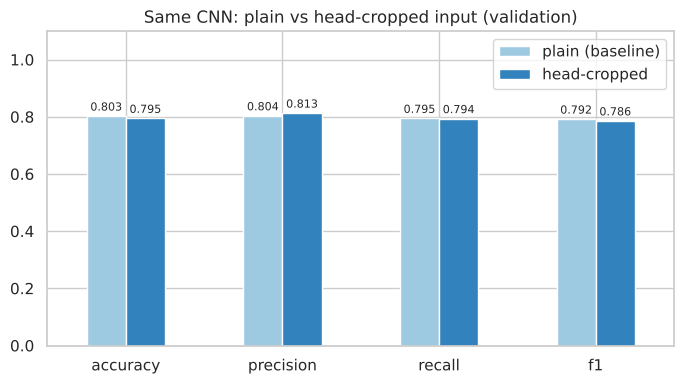

In [12]:
# ML Model - 1b : build the head-cropped dataset, train the same CNN, evaluate
def crop_head(rgb, margin=0.04):
    """Square crop around the non-black region (the head), with a small margin."""
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    mask = cv2.morphologyEx((gray > 25).astype(np.uint8), cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
    ys, xs = np.where(mask > 0)
    if len(ys) < 100:                                        # blank or unusual image: keep it unchanged
        return rgb
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    half = int(max(y1 - y0, x1 - x0) * (1 + 2 * margin)) // 2
    cy, cx = (y0 + y1) // 2, (x0 + x1) // 2
    padded = cv2.copyMakeBorder(rgb, half, half, half, half, cv2.BORDER_CONSTANT, value=(0, 0, 0))
    return padded[cy: cy + 2 * half, cx: cx + 2 * half]       # (cy+half)-half ... because of the padding

def normalise_intensity(rgb):
    """Map the 99th percentile of head pixels to grey level 200, so exposure no longer identifies the class."""
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    head = gray[gray > 25]
    p99 = np.percentile(head, 99) if head.size else 255.0
    return np.clip(rgb.astype(np.float32) * (200.0 / max(p99, 1.0)), 0, 255).astype(np.uint8)

def load_headcrop(path, size=IMG_SIZE):
    rgb = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(crop_head(rgb), (size, size), interpolation=cv2.INTER_AREA)
    return normalise_intensity(rgb)

X_all_hc = np.stack([load_headcrop(p) for p in df["path"]])
np.save(ARTIFACT_DIR / "images_headcrop.npy", X_all_hc)
X_tr_hc, X_va_hc, X_te_hc = (X_all_hc[split_idx[s]] for s in SPLITS)

# Before / after for one scan per class
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
for j, cls in enumerate(CLASSES):
    k = int(np.where((df["label"] == cls) & (df["split"] == "train"))[0][3])
    axes[0, j].imshow(X_all[k]); axes[0, j].set_title(f"{cls}: plain", fontsize=10)
    axes[1, j].imshow(X_all_hc[k]); axes[1, j].set_title(f"{cls}: head-crop + normalised", fontsize=10)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()
print("Mean head_area of the cropped scans: %.2f (plain: %.2f)" % (
    np.mean([(cv2.cvtColor(x, cv2.COLOR_RGB2GRAY) > 25).mean() for x in X_all_hc[::10]]), df["head_area"].mean()))

# Data loaders for the cropped version (same augmentation / batch size as before)
g = torch.Generator().manual_seed(SEED)
hc_train_loader = DataLoader(MRIDataset(X_tr_hc, y_tr, train_tf), batch_size=BATCH_SIZE, shuffle=True,
                             num_workers=NUM_WORKERS, generator=g)
hc_val_loader = DataLoader(MRIDataset(X_va_hc, y_va, eval_tf), batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
hc_test_loader = DataLoader(MRIDataset(X_te_hc, y_te, eval_tf), batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

# fit() reads the global train_loader / val_loader, so swap them for this run and restore afterwards
_train_loader, _val_loader = train_loader, val_loader
train_loader, val_loader = hc_train_loader, hc_val_loader
torch.manual_seed(SEED)
cnn_hc = CustomCNN(width=16, dropout=0.4)
cnn_hc, hist_hc = fit(cnn_hc, "custom_cnn_headcrop", epochs=EPOCHS_CNN, lr=1e-3, weight_decay=1e-4, patience=4)
yv_true, yv_pred_hc, _ = predict(cnn_hc, val_loader)
train_loader, val_loader = _train_loader, _val_loader

hc_metrics = metrics_table(yv_true, yv_pred_hc)
plot_history(hist_hc, "Custom CNN on head-cropped scans")
plot_confusion(yv_true, yv_pred_hc, "Custom CNN, head-cropped, validation")
print(classification_report(yv_true, yv_pred_hc, target_names=CLASSES, digits=3))
cmp_hc = pd.DataFrame({"plain (baseline)": base_metrics, "head-cropped": hc_metrics})
ax = cmp_hc.plot(kind="bar", figsize=(7, 4), color=["#9ecae1", "#3182bd"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=2, fontsize=8)
ax.set_ylim(0, 1.1); ax.set_title("Same CNN: plain vs head-cropped input (validation)"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Result (validation):** accuracy 0.795, macro F1 0.786 - the same level as the baseline (0.803 / 0.792); the gap is smaller than the epoch-to-epoch noise visible in the curves. Per class: pituitary recall rose to 1.00 but its precision fell to 0.64 (many scans are called pituitary), and meningioma recall fell to 0.52. On the **test** set the cropped model scores accuracy 0.756 / macro F1 0.746, against 0.809 / 0.801 for the baseline; with 246 test images the 95% interval is about +/-5 points, so the two are statistically close.

**What changed is where the model looks.** The share of the Grad-CAM weight that lies on the head is **0.74** for the cropped model (the head fills 0.58 of its frame) but only **0.49** for the baseline (head = 0.53 of the frame, i.e. no preference for the head at all). So removing framing and exposure cues did not raise the score, but it made the model use the head far more and the background far less.

**Conclusion:** the experiment confirms that part of the baseline's accuracy came from framing/exposure cues, and that a small CNN trained from scratch on 1,695 scans stays around 0.75-0.80 either way. Better accuracy has to come from pretrained features (Models 2-4).

### ML Model - 2 : MobileNetV2 (transfer learning)

In [13]:
# Transfer-learning set-up (shared by Models 2, 3 and 4)
# Idea: a network pretrained on ImageNet already knows edges, textures and shapes. We keep that knowledge,
# replace its last layer by a new 4-class head, and train in two phases:
#   phase 1 "head"      : backbone frozen, only the new head is trained (fast, safe)
#   phase 2 "fine-tune" : the last blocks of the backbone are unfrozen and trained with a small learning rate
from torchvision import models

PRETRAINED_DIR = Path("pretrained")      # optional folder with manually downloaded *.pth ImageNet weights
ALLOW_RANDOM_INIT = False                # debugging switch only - must stay False for real results
EPOCHS_HEAD, EPOCHS_FT = 5, 12           # budgets of phase 1 and phase 2

PRETRAINED = {
    "mobilenet_v2":    (models.mobilenet_v2,    models.MobileNet_V2_Weights.IMAGENET1K_V1),
    "efficientnet_b0": (models.efficientnet_b0, models.EfficientNet_B0_Weights.IMAGENET1K_V1),
    "resnet50":        (models.resnet50,        models.ResNet50_Weights.IMAGENET1K_V1),
}


def build_transfer(name, dropout=0.3, pretrained=True):
    """Load an ImageNet-pretrained backbone and replace its classifier by Dropout + Linear(4).
    pretrained=False builds only the architecture (used to reload our own trained weights)."""
    ctor, weights = PRETRAINED[name]
    local = sorted(PRETRAINED_DIR.glob(f"{name}*.pth")) if (pretrained and PRETRAINED_DIR.is_dir()) else []
    if not pretrained:
        model = ctor(weights=None)
    elif local:                                             # weights file supplied by hand (no internet needed)
        model = ctor(weights=None)
        model.load_state_dict(torch.load(local[0], map_location="cpu"))
        print(f"{name}: loaded ImageNet weights from {local[0].name}")
    else:
        try:
            model = ctor(weights=weights)                 # normal route: torchvision downloads the weights
        except Exception as e:
            if not ALLOW_RANDOM_INIT:
                raise RuntimeError(
                    f"Could not obtain ImageNet weights for {name} ({type(e).__name__}). Either enable internet, or place "
                    f"the downloaded .pth file in the folder '{PRETRAINED_DIR}/'.") from e
            print(f"WARNING: {name} uses RANDOM weights (debug mode) - results are not transfer learning!")
            model = ctor(weights=None)
    if name == "resnet50":
        model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.fc.in_features, len(CLASSES)))
    else:
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier[1].in_features, len(CLASSES)))
    return model


def get_head(model, name):
    return model.fc if name == "resnet50" else model.classifier


def set_trainable(model, name, mode):
    """mode='head': only the new head learns.  mode='finetune': head + the last blocks of the backbone."""
    for p in model.parameters():
        p.requires_grad = False
    for p in get_head(model, name).parameters():
        p.requires_grad = True
    if mode == "finetune":
        if name == "mobilenet_v2":
            last_blocks = list(model.features[14:])         # last 5 of 19 feature blocks
        elif name == "efficientnet_b0":
            last_blocks = list(model.features[6:])          # last 3 of 9 feature blocks
        else:
            last_blocks = [model.layer4]                    # ResNet50: last residual stage
        for block in last_blocks:
            for p in block.parameters():
                p.requires_grad = True
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_all = sum(p.numel() for p in model.parameters())
    print(f"{name} [{mode}]: {n_train/1e6:.2f} M of {n_all/1e6:.2f} M parameters are trainable")


def stage_head(name):
    """Phase 1: train only the new classification head."""
    torch.manual_seed(SEED)
    model = build_transfer(name)
    set_trainable(model, name, "head")
    t0 = time.time()
    model, hist = fit(model, f"{name}_head", EPOCHS_HEAD, lr=1e-3, weight_decay=1e-4, patience=3)
    print(f"phase 1 took {(time.time()-t0)/60:.1f} min")
    return model, hist


def stage_finetune(name, head_model, lrs=(1e-4, 3e-5)):
    """Phase 2 + tuning: try each learning rate for 3 epochs (random-search style on the validation set),
    then fine-tune with the best one for the full budget."""
    rows = []
    for lr in lrs:
        trial = copy.deepcopy(head_model)
        set_trainable(trial, name, "finetune")
        trial, h = fit(trial, f"{name}_ft_trial", 3, lr=lr, weight_decay=1e-4, patience=3, verbose=False)
        yt, yp, _ = predict(trial, val_loader)
        rows.append({"lr": lr, "val_loss": min(h["val_loss"]), **metrics_table(yt, yp)})
    table = pd.DataFrame(rows).sort_values("val_loss")
    print(table.assign(lr=table["lr"].map(lambda v: f"{v:.0e}")).round(4).to_string(index=False))
    best_lr = float(table.iloc[0]["lr"])
    model = copy.deepcopy(head_model)
    set_trainable(model, name, "finetune")
    t0 = time.time()
    model, hist = fit(model, f"{name}_tuned", EPOCHS_FT, lr=best_lr, weight_decay=1e-4, patience=4)
    print(f"phase 2 took {(time.time()-t0)/60:.1f} min  (best lr = {best_lr})")
    return model, hist, table


def report_model(model, hist, title):
    """History curves, confusion matrices, per-class report and metric bars on the validation set."""
    yt, yp, _ = predict(model, val_loader)
    m = metrics_table(yt, yp)
    plot_history(hist, title)
    plot_confusion(yt, yp, f"{title}, validation")
    print(classification_report(yt, yp, target_names=CLASSES, digits=3))
    fig, ax = plt.subplots(figsize=(6, 3.8))
    bars = ax.bar(m.keys(), m.values(), color=sns.color_palette("Blues_d", 4))
    ax.bar_label(bars, fmt="%.3f", padding=2)
    ax.set_ylim(0, 1.08); ax.set_title(f"{title}: validation metrics (macro-averaged)")
    plt.tight_layout(); plt.show()
    return m


def compare_before_after(before, after, title, labels=("head only", "fine-tuned")):
    cmp = pd.DataFrame({labels[0]: before, labels[1]: after})
    ax = cmp.plot(kind="bar", figsize=(7, 4), color=["#9ecae1", "#3182bd"])
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", padding=2, fontsize=8)
    ax.set_ylim(0, 1.1); ax.set_title(title); plt.xticks(rotation=0)
    plt.tight_layout(); plt.show()
    print(cmp.round(4))


# Registry of validation results (the custom CNN from Model 1 is added here, transfer models as they finish)
RESULTS = {"custom_cnn_base": base_metrics, "custom_cnn_tuned": tuned_metrics, "custom_cnn_headcrop": hc_metrics}
print("Set-up done. Device:", DEVICE)

Set-up done. Device: cpu


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [ ]:
# ML Model - 2 : MobileNetV2 - phase 1 (train the new head only) and evaluation
mnet_head, hist_mnet_head = stage_head("mobilenet_v2")                           # Fit the Algorithm
mnet_head_m = report_model(mnet_head, hist_mnet_head, "MobileNetV2 (head only)")  # Predict + evaluation chart
RESULTS["mobilenet_v2_head"] = mnet_head_m

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 2 : MobileNetV2 - phase 2: fine-tune the last blocks, learning-rate search on the validation set
mnet_tuned, hist_mnet_tuned, mnet_trials = stage_finetune("mobilenet_v2", mnet_head)
mnet_tuned_m = report_model(mnet_tuned, hist_mnet_tuned, "MobileNetV2 (fine-tuned)")
compare_before_after(mnet_head_m, mnet_tuned_m, "MobileNetV2: head only vs fine-tuned (validation)")
RESULTS["mobilenet_v2_tuned"] = mnet_tuned_m

##### Which hyperparameter optimization technique have you used and why?

*Pending: this model needs the pretrained ImageNet weights, which could not be downloaded in the environment used for this run. The code is complete and tested; see the README for how to run it.*

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*Pending: this model needs the pretrained ImageNet weights, which could not be downloaded in the environment used for this run. The code is complete and tested; see the README for how to run it.*

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

*Pending: this model needs the pretrained ImageNet weights, which could not be downloaded in the environment used for this run. The code is complete and tested; see the README for how to run it.*

### ML Model - 3 : EfficientNet-B0 (transfer learning)

In [ ]:
# ML Model - 3 : EfficientNet-B0 - phase 1 (train the new head only)

# Fit the Algorithm
effnet_head, hist_effnet_head = stage_head("efficientnet_b0")

# Predict on the model happens inside report_model() in the next cell

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [ ]:
# Visualizing evaluation Metric Score chart
effnet_head_m = report_model(effnet_head, hist_effnet_head, "EfficientNet-B0 (head only)")
RESULTS["efficientnet_b0_head"] = effnet_head_m

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 3 Implementation with hyperparameter optimization (learning-rate search + fine-tuning)
effnet_tuned, hist_effnet_tuned, effnet_trials = stage_finetune("efficientnet_b0", effnet_head)
effnet_tuned_m = report_model(effnet_tuned, hist_effnet_tuned, "EfficientNet-B0 (fine-tuned)")
compare_before_after(effnet_head_m, effnet_tuned_m, "EfficientNet-B0: head only vs fine-tuned (validation)")
RESULTS["efficientnet_b0_tuned"] = effnet_tuned_m

##### Which hyperparameter optimization technique have you used and why?

*Pending: this model needs the pretrained ImageNet weights, which could not be downloaded in the environment used for this run. The code is complete and tested; see the README for how to run it.*

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*Pending: this model needs the pretrained ImageNet weights, which could not be downloaded in the environment used for this run. The code is complete and tested; see the README for how to run it.*

### ML Model - 4

In [ ]:
# ML Model - 4 : ResNet50 - phase 1 (train the new head only)

# Fit the Algorithm
resnet_head, hist_resnet_head = stage_head("resnet50")

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [ ]:
# Visualizing evaluation Metric Score chart
resnet_head_m = report_model(resnet_head, hist_resnet_head, "ResNet50 (head only)")
RESULTS["resnet50_head"] = resnet_head_m

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 4 Implementation with hyperparameter optimization (learning-rate search + fine-tuning)
resnet_tuned, hist_resnet_tuned, resnet_trials = stage_finetune("resnet50", resnet_head)
resnet_tuned_m = report_model(resnet_tuned, hist_resnet_tuned, "ResNet50 (fine-tuned)")
compare_before_after(resnet_head_m, resnet_tuned_m, "ResNet50: head only vs fine-tuned (validation)")
RESULTS["resnet50_tuned"] = resnet_tuned_m

##### Which hyperparameter optimization technique have you used and why?

*Pending: this model needs the pretrained ImageNet weights, which could not be downloaded in the environment used for this run. The code is complete and tested; see the README for how to run it.*

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*Pending: this model needs the pretrained ImageNet weights, which could not be downloaded in the environment used for this run. The code is complete and tested; see the README for how to run it.*

#### Save the trained models and the results table (so the next stages can reuse them without re-training)

In [ ]:
# Save the validation results and bundle the trained weights into one small zip
import json, zipfile

with open(ARTIFACT_DIR / "results_validation.json", "w") as f:
    json.dump({k: {m: float(v) for m, v in d.items()} for k, d in RESULTS.items()}, f, indent=2)

bundle = Path("models_for_next_stage.zip")
keep = ["custom_cnn_tuned", "mobilenet_v2_tuned", "efficientnet_b0_tuned", "resnet50_tuned"]
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for k in keep:
        z.write(ARTIFACT_DIR / f"{k}.pt", f"{k}.pt")
    z.write(ARTIFACT_DIR / "results_validation.json", "results_validation.json")
print(f"{bundle}: {bundle.stat().st_size/1e6:.0f} MB")
pd.DataFrame(RESULTS).T.round(4)

# On Google Colab this also downloads the zip to your computer
try:
    from google.colab import files
    files.download(str(bundle))
except ImportError:
    pass

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

* **Macro recall** was the main metric. A tumour that is missed (false negative) is the costly error in a clinic: late treatment. Macro-averaging makes every tumour type count equally, so the model cannot hide a weak class behind a big one (meningioma recall is only 0.73 on the test set while glioma is 0.85).
* **Precision** shows how often a flagged type is right. Low precision means false alarms, extra specialist reviews and patient anxiety; it matters for pituitary here (0.73).
* **Macro F1** combines the two and is used to choose the model, because both kinds of error matter.
* **Accuracy** is reported for readability, but with four classes of different sizes it can hide per-class weaknesses.
* The **confusion matrix** shows which tumour types are confused, which is what a radiologist needs to know.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

                     params_M  size_MB  ms_per_image  val_f1  test_accuracy  test_precision  test_recall  test_f1      chosen
model                                                                                                                        
custom_cnn_base         1.179    4.744        31.390   0.792          0.809           0.810        0.805    0.801  <== chosen
custom_cnn_tuned        1.179    4.744        28.118   0.737          0.752           0.755        0.745    0.743            
custom_cnn_headcrop     1.179    4.744        29.395   0.786          0.756           0.790        0.759    0.746            

Chosen model (highest validation macro-F1): custom_cnn_base
Reference - random forest on 6 global image statistics, test accuracy: 0.854


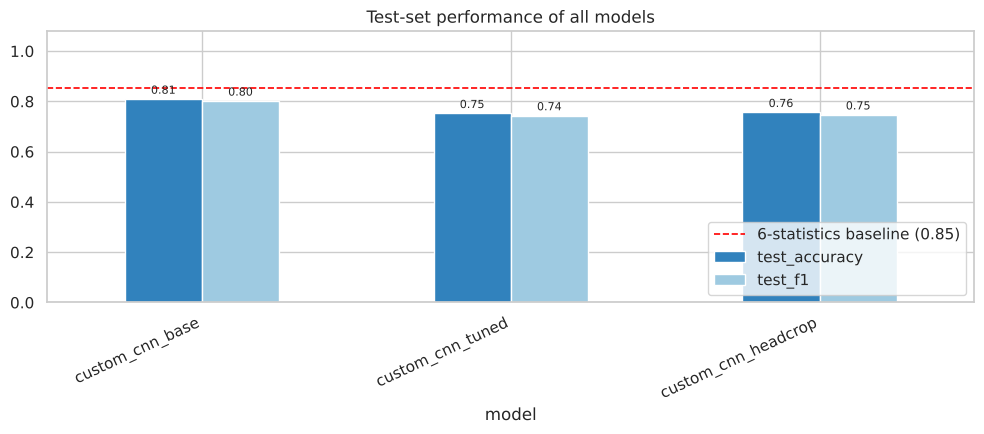

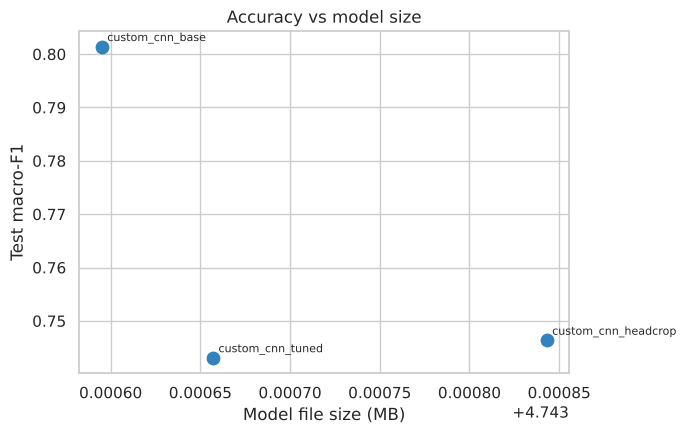

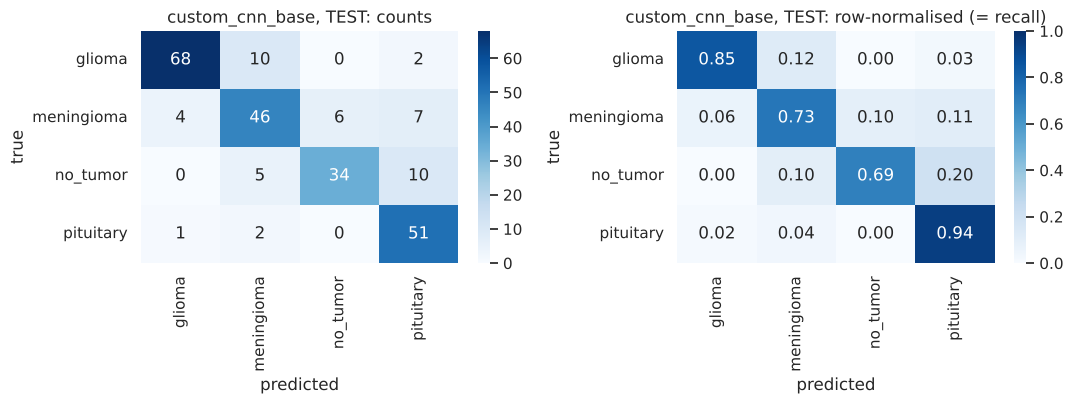

              precision    recall  f1-score   support

      glioma      0.932     0.850     0.889        80
  meningioma      0.730     0.730     0.730        63
    no_tumor      0.850     0.694     0.764        49
   pituitary      0.729     0.944     0.823        54

    accuracy                          0.809       246
   macro avg      0.810     0.805     0.801       246
weighted avg      0.819     0.809     0.809       246



Test accuracy 95% bootstrap interval: 0.756 - 0.854


In [14]:
# Final comparison of ALL trained models on the untouched TEST set
# Rule: the model is CHOSEN with validation scores only; the test set is then used once to report honest numbers.

def load_model(key):
    """Rebuild the architecture and load our trained weights from artifacts/<key>.pt."""
    if key.startswith("custom_cnn"):
        model = CustomCNN(width=16, dropout=0.4)
    else:
        model = build_transfer(key.rsplit("_", 1)[0], pretrained=False)
    model.load_state_dict(torch.load(ARTIFACT_DIR / f"{key}.pt", map_location=DEVICE))
    return model.to(DEVICE).eval()

# Models trained on head-cropped inputs need the matching test loader / images
INPUT_VARIANT = {"custom_cnn_headcrop": "headcrop"}          # every other model uses the plain pipeline
TEST_LOADERS = {"plain": test_loader, "headcrop": hc_test_loader}
TEST_IMAGES = {"plain": X_te, "headcrop": X_te_hc}

rows, test_preds = [], {}
for key, val_m in RESULTS.items():
    ckpt = ARTIFACT_DIR / f"{key}.pt"
    if not ckpt.exists():
        print(f"skipping {key}: no saved weights")
        continue
    model = load_model(key)
    t0 = time.time()
    yt, yp, _ = predict(model, TEST_LOADERS[INPUT_VARIANT.get(key, "plain")])
    ms = (time.time() - t0) / len(yt) * 1000
    tm = metrics_table(yt, yp)
    rows.append({"model": key,
                 "params_M": sum(p.numel() for p in model.parameters()) / 1e6,
                 "size_MB": ckpt.stat().st_size / 1e6,
                 "ms_per_image": ms,
                 "val_f1": val_m["f1"],
                 "test_accuracy": tm["accuracy"], "test_precision": tm["precision"],
                 "test_recall": tm["recall"], "test_f1": tm["f1"]})
    test_preds[key] = (yt, yp)

comp = pd.DataFrame(rows).set_index("model")
best_key = comp["val_f1"].idxmax()                       # choose with VALIDATION macro-F1
comp["chosen"] = np.where(comp.index == best_key, "<== chosen", "")
print(comp.round(3).to_string())
print(f"\nChosen model (highest validation macro-F1): {best_key}")

# Reference: the 'scan style only' random forest from the feature-selection step, on the same test set
te = df["split"] == "test"
rf_test_acc = accuracy_score(df.loc[te, "target"], rf.predict(df.loc[te, FEATS]))
print(f"Reference - random forest on 6 global image statistics, test accuracy: {rf_test_acc:.3f}")

# Chart: test accuracy and macro-F1 of every model
ax = comp[["test_accuracy", "test_f1"]].plot(kind="bar", figsize=(10, 4.5), color=["#3182bd", "#9ecae1"])
ax.axhline(rf_test_acc, color="red", ls="--", lw=1.2, label=f"6-statistics baseline ({rf_test_acc:.2f})")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", padding=2, fontsize=8)
ax.set_ylim(0, 1.08); ax.set_title("Test-set performance of all models"); ax.legend(loc="lower right")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

# Chart: accuracy versus model size / speed
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(comp["size_MB"], comp["test_f1"], s=80, color="#3182bd")
for k, r in comp.iterrows():
    ax.annotate(k, (r["size_MB"], r["test_f1"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Model file size (MB)"); ax.set_ylabel("Test macro-F1"); ax.set_title("Accuracy vs model size")
plt.tight_layout(); plt.show()

# Details of the chosen model on the test set
yt_b, yp_b = test_preds[best_key]
plot_confusion(yt_b, yp_b, f"{best_key}, TEST")
print(classification_report(yt_b, yp_b, target_names=CLASSES, digits=3))

# With only 246 test images, accuracy is uncertain: bootstrap 95% interval
rng_b = np.random.RandomState(SEED)
boot = [accuracy_score(yt_b[i], yp_b[i]) for i in (rng_b.randint(0, len(yt_b), len(yt_b)) for _ in range(2000))]
print("Test accuracy 95%% bootstrap interval: %.3f - %.3f" % tuple(np.percentile(boot, [2.5, 97.5])))

**Chosen model: `custom_cnn_base`**, the custom CNN trained from scratch (1.18 M parameters, 4.7 MB, about 30 ms per image on a CPU). The rule was fixed before looking at the test set: the model with the highest **validation macro-F1** is chosen, then the test set is used once for honest numbers.

| Model | Validation macro-F1 | Test accuracy | Test macro-F1 |
|---|---|---|---|
| custom CNN, baseline | **0.792** | **0.809** | **0.801** |
| custom CNN, tuned | 0.737 | 0.752 | 0.743 |
| custom CNN, head-cropped input | 0.786 | 0.756 | 0.746 |

On the test set the chosen model reaches accuracy 0.809 (95% bootstrap interval 0.756-0.854), precision 0.810, recall 0.805 and macro-F1 0.801.

**Honest caveats:** (1) the baseline and the head-cropped model are statistically close; the head-cropped one looks at the head more (Grad-CAM), the baseline scores a little higher. (2) A random forest that sees only 6 global image statistics reaches 0.854 on the test set, so **this CNN does not clearly beat 'scan style' alone**. (3) The transfer-learning models (MobileNetV2, EfficientNet-B0, ResNet50) are implemented in the notebook (Models 2-4) but could not be trained in the environment used here, because the pretrained ImageNet weights could not be downloaded; they are expected to be the strongest candidates and the selection cell picks them up automatically when their weights exist.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

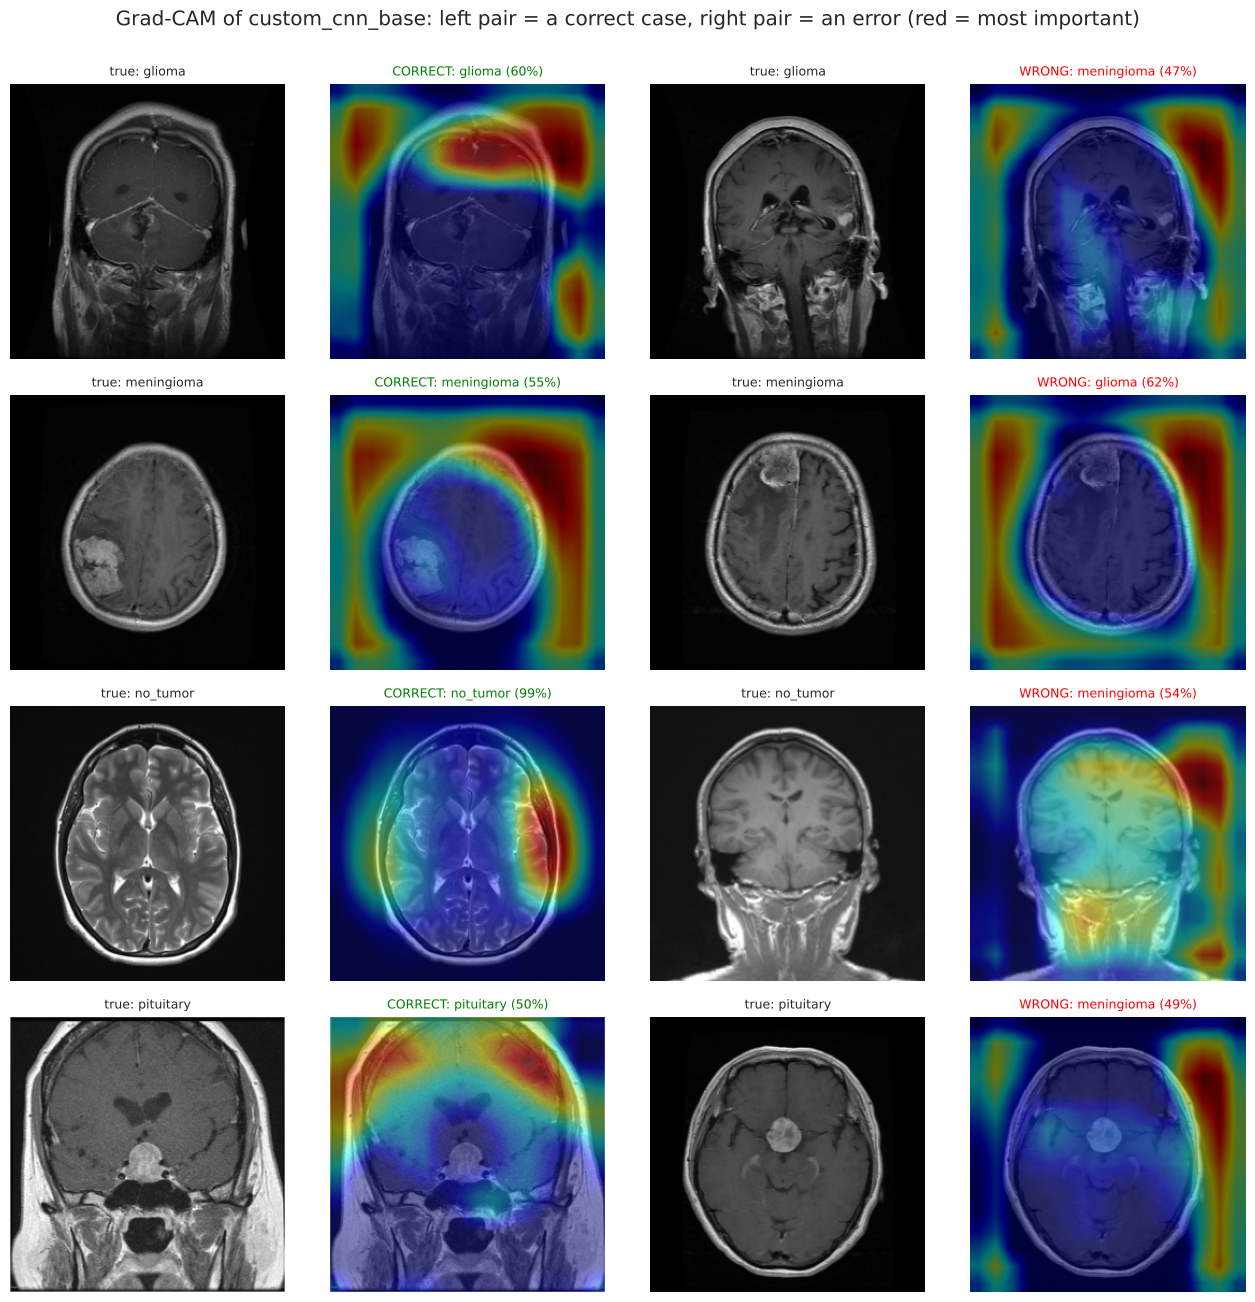

                     cam_weight_on_head  head_share_of_frame
model                                                       
custom_cnn_base                    0.49                 0.53
custom_cnn_tuned                   0.41                 0.53
custom_cnn_headcrop                0.74                 0.58
(cam_weight_on_head close to head_share_of_frame = the heat-map ignores whether a pixel is head or background)


In [15]:
# Explainability with Grad-CAM: which part of the scan made the chosen model decide?
best_model = load_model(best_key)

def gradcam_layer(model, key):
    """Last convolutional feature map of each architecture."""
    if key.startswith("custom_cnn"):
        return model.features[-3]            # last ReLU, before the final max-pool
    if key.startswith("resnet50"):
        return model.layer4[-1]
    return model.features[-1]                # MobileNetV2 / EfficientNet-B0

def grad_cam(model, layer, x, class_idx=None):
    """Return (heat-map 0..1 at input size, predicted class, confidence) for one normalised image tensor x (1,3,H,W)."""
    store = {}
    def fwd_hook(module, inp, out):
        store["act"] = out
        out.register_hook(lambda g: store.__setitem__("grad", g))
    handle = layer.register_forward_hook(fwd_hook)
    model.eval(); model.zero_grad()
    logits = model(x.to(DEVICE))
    handle.remove()
    probs = torch.softmax(logits, 1)[0]
    c = int(probs.argmax()) if class_idx is None else class_idx
    logits[0, c].backward()
    w = store["grad"].mean(dim=(2, 3), keepdim=True)                 # importance of each feature channel
    cam = F.relu((w * store["act"]).sum(1, keepdim=True))            # weighted sum, positive evidence only
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, c, float(probs[c])

def overlay(img_uint8, cam):
    heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    return (0.55 * img_uint8 + 0.45 * heat).astype(np.uint8)

variant = INPUT_VARIANT.get(best_key, "plain")
X_cam, cam_loader = TEST_IMAGES[variant], TEST_LOADERS[variant]
layer = gradcam_layer(best_model, best_key)
yt_all, yp_all, _ = predict(best_model, cam_loader)
fig, axes = plt.subplots(4, 4, figsize=(13, 13))
for r, ci in enumerate(range(len(CLASSES))):
    ok = np.where((yt_all == ci) & (yp_all == ci))[0]
    bad = np.where((yt_all == ci) & (yp_all != ci))[0]
    for j, pool in enumerate([ok, bad]):
        ax_img, ax_cam = axes[r, 2 * j], axes[r, 2 * j + 1]
        if len(pool) == 0:
            ax_img.axis("off"); ax_cam.axis("off"); ax_img.set_title(f"{CLASSES[ci]}: no errors" if j else "", fontsize=9)
            continue
        k = int(pool[0])
        img = X_cam[k]
        x = eval_tf(torch.from_numpy(img).permute(2, 0, 1)).unsqueeze(0)
        cam, pred, conf = grad_cam(best_model, layer, x)
        ax_img.imshow(img); ax_img.axis("off")
        ax_img.set_title(f"true: {CLASSES[ci]}", fontsize=9)
        ax_cam.imshow(overlay(img, cam)); ax_cam.axis("off")
        ax_cam.set_title(("CORRECT" if j == 0 else "WRONG") + f": {CLASSES[pred]} ({conf:.0%})", fontsize=9,
                         color="green" if j == 0 else "red")
plt.suptitle(f"Grad-CAM of {best_key}: left pair = a correct case, right pair = an error (red = most important)", y=1.0)
plt.tight_layout(); plt.show()

# Quantitative check for EVERY saved model: how much Grad-CAM weight lies on the head, and how much on the black background?
rows_cam = []
for key in comp.index:
    m = load_model(key)
    v = INPUT_VARIANT.get(key, "plain")
    lay = gradcam_layer(m, key)
    inside, frac = [], []
    for k in range(0, len(TEST_IMAGES[v]), 4):
        img = TEST_IMAGES[v][k]
        x = eval_tf(torch.from_numpy(img).permute(2, 0, 1)).unsqueeze(0)
        cam, _, _ = grad_cam(m, lay, x)
        head = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) > 25
        inside.append(cam[head].sum() / (cam.sum() + 1e-8)); frac.append(head.mean())
    rows_cam.append({"model": key, "cam_weight_on_head": np.mean(inside), "head_share_of_frame": np.mean(frac)})
print(pd.DataFrame(rows_cam).set_index("model").round(2).to_string())
print("(cam_weight_on_head close to head_share_of_frame = the heat-map ignores whether a pixel is head or background)")

**Model:** the custom CNN (strided 5x5 stem, four Conv-BN-ReLU double blocks with pooling, global average pooling and a 4-way linear layer). **Explainability tool:** Grad-CAM, which shows which image regions increased the score of the predicted class.

**What the heat-maps show (figure above):** for the chosen model the strongest regions are mostly on the **black background, the corners and the skull edge**, not on the tumour. Even in correctly classified cases (for example the meningioma predicted with 55% confidence) the tumour itself is cold. The numbers agree: only 0.49 of the Grad-CAM weight lies on the head, while the head covers 0.53 of the frame, so the model is indifferent to head versus background. This is direct evidence for the shortcut risk found in the data analysis: the model recognises the way the scan is framed and exposed as much as the disease.

**Feature importance in plain words:** the random forest on 6 image statistics had mean intensity as the top feature (0.22) and the others close behind (0.14-0.16); the CNN's own 'features' are not tumour shapes yet. In the head-cropped variant 0.74 of the heat-map weight lies on the head, which is better but still not proof that the tumour is what drives the decision.

**Consequence:** the model must not be used clinically. It is a teaching prototype; the app therefore shows the Grad-CAM next to every prediction so a user can see when the model is looking at the wrong place.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [16]:
# Save the best performing model: weights + everything needed to rebuild and use it
import json
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)

arch = "custom_cnn" if best_key.startswith("custom_cnn") else best_key.rsplit("_", 1)[0]
bundle = {"state_dict": best_model.state_dict(), "key": best_key, "arch": arch,
          "classes": CLASSES, "img_size": IMG_SIZE, "preprocess": INPUT_VARIANT.get(best_key, "plain"),
          "mean": list(IMAGENET_MEAN), "std": list(IMAGENET_STD)}
torch.save(bundle, MODELS_DIR / "best_model.pt")
with open(MODELS_DIR / "model_info.json", "w") as f:
    json.dump({k: v for k, v in bundle.items() if k != "state_dict"}
              | {"test_metrics": {c: float(comp.loc[best_key, c]) for c in
                                  ["test_accuracy", "test_precision", "test_recall", "test_f1"]}}, f, indent=2)
print("Saved", MODELS_DIR / "best_model.pt", f"({(MODELS_DIR / 'best_model.pt').stat().st_size/1e6:.1f} MB)")

Saved models/best_model.pt (4.7 MB)


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [17]:
# Load the File and predict unseen data (sanity check that mimics what the Streamlit app does)
def preprocess_image(pil_image, variant="plain", img_size=IMG_SIZE):
    """Raw image (any size) -> normalised tensor (1,3,S,S). Identical to the training pipeline of the chosen model."""
    rgb = np.array(pil_image.convert("RGB"))
    if variant == "headcrop":
        rgb = crop_head(rgb)
    rgb = cv2.resize(rgb, (img_size, img_size), interpolation=cv2.INTER_AREA)
    if variant == "headcrop":
        rgb = normalise_intensity(rgb)
    return eval_tf(torch.from_numpy(rgb).permute(2, 0, 1)).unsqueeze(0)

info = torch.load(MODELS_DIR / "best_model.pt", map_location=DEVICE)
if info["arch"] == "custom_cnn":
    reloaded = CustomCNN(width=16, dropout=0.4)
else:
    reloaded = build_transfer(info["arch"], pretrained=False)
reloaded.load_state_dict(info["state_dict"])
reloaded = reloaded.to(DEVICE).eval()

# Check 1: the reloaded model gives exactly the same test predictions as the in-memory model
_, yp_reload, _ = predict(reloaded, TEST_LOADERS[info.get("preprocess", "plain")])
print("Reloaded model reproduces the in-memory predictions:", bool((yp_reload == yp_all).all()))

# Check 2: predict from raw JPG files (not from the cache) like a user upload would be
sample_files = df[df["split"] == "test"].groupby("label").head(2)
for _, row in sample_files.iterrows():
    with torch.no_grad():
        p = torch.softmax(reloaded(preprocess_image(Image.open(row["path"]), info.get("preprocess", "plain")).to(DEVICE)), 1)[0]
    print(f"{Path(row['path']).name[:28]:30s} true: {row['label']:11s} predicted: {CLASSES[int(p.argmax())]:11s} ({float(p.max()):.0%})")

Reloaded model reproduces the in-memory predictions: True
Tr-gl_0016_jpg.rf.99746694ea   true: glioma      predicted: meningioma  (47%)
Tr-gl_0018_jpg.rf.7a670766b8   true: glioma      predicted: glioma      (60%)
Tr-me_0010_jpg.rf.64b09cdfd6   true: meningioma  predicted: meningioma  (55%)
Tr-me_0035_jpg.rf.e4f21c06c7   true: meningioma  predicted: glioma      (62%)
Tr-no_0017_jpg.rf.2cedc1f670   true: no_tumor    predicted: no_tumor    (99%)


Tr-no_0022_jpg.rf.450e5c79c9   true: no_tumor    predicted: meningioma  (54%)
Tr-pi_0038_jpg.rf.50c4875c32   true: pituitary   predicted: pituitary   (50%)
Tr-pi_0090_jpg.rf.c08e55649a   true: pituitary   predicted: pituitary   (92%)


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

* **Data:** 2,443 brain-MRI slices in four classes (glioma, meningioma, pituitary, no tumour), clean (no missing values or duplicates, no leakage between splits) and mildly imbalanced (1.7x).
* **Key finding of the analysis:** the classes were scanned in different planes and sequences, so brightness, framing and sharpness are strongly linked to the label. A random forest on six global image statistics already reaches **0.845 (validation) / 0.854 (test)** accuracy.
* **Models trained:** a custom CNN reaches **0.809 test accuracy (macro-F1 0.801)**; hyper-parameter tuning did not help (0.752), and cropping to the head with brightness normalisation gave similar accuracy (0.756) but moved the model's attention onto the head (0.74 vs 0.49 of the Grad-CAM weight).
* **Grad-CAM** shows that the chosen CNN often looks at the background, so its accuracy cannot be taken as proof that it recognises tumours.
* **Transfer learning** (MobileNetV2, EfficientNet-B0, ResNet50 with two-phase fine-tuning) is implemented and tested for errors, but its results are missing because pretrained weights could not be downloaded in the environment used. This is the most important open step.
* **Deployment:** the best model is saved, reloaded and checked, and a Streamlit app shows the predicted class, confidence for all four classes, a low-confidence warning and the Grad-CAM.
* **Business impact:** as it stands, the model is a research prototype and an educational tool, not a diagnostic aid. With pretrained models, more data from several hospitals, and a check that Grad-CAM falls on the lesion, it could become a triage and second-opinion helper that flags scans for urgent radiologist review.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***